# [통계적 검정과 인과추론] 종합 과제 — A/B 테스트

**주제:** 광고(ad)를 보여주면 공익광고(PSA)를 보여줄 때보다 구매 전환율이 높아지는가?

| 항목 | 내용 |
|---|---|
| 데이터 | Kaggle — *Marketing A/B Testing* (faviovaz) |
| 출처 | https://www.kaggle.com/datasets/faviovaz/marketing-ab-testing |
| 내려받은 날짜 | 2026-11-06 *(직접 받은 날짜로 수정하세요)* |
| 파일 | `marketing_AB.csv` (588,101행) |
| 흐름 | 0 데이터 선정 → 1 데이터 점검 → 2 가설 → 3 검정 선택 → 4 검정·3종 세트 → 5 한 걸음 더 (A·B·C·D 전부) → 6 의사결정 |

> 노트북을 위에서부터 끝까지 다시 실행하면 같은 결과가 나오도록 난수 시드를 고정했습니다 (`SEED = 42`).

## ⚙️ 환경 설정

In [10]:
# ── 라이브러리 불러오기 ─────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
from scipy import stats

# statsmodels: 비율 검정, 신뢰구간, 검정력, 다중검정 보정
from statsmodels.stats.proportion import (proportions_ztest, proportion_confint,
                                          confint_proportions_2indep, proportion_effectsize)
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.contingency_tables import StratifiedTable

import warnings
warnings.filterwarnings("ignore")

# ── 재현성: 난수 시드 고정 ─────────────────────────────────────────
SEED = 42
np.random.seed(SEED)                  # 구식 API용
rng = np.random.default_rng(SEED)     # 신식 Generator (이 노트북에서는 주로 이것을 사용)

# ── 그래프 스타일 (주의: seaborn 스타일은 폰트를 초기화하므로 폰트 설정보다 먼저 호출) ──
sns.set_style("whitegrid")

# ── 한글 폰트 설정 (OS별로 있는 폰트를 자동 선택) ─────────────────
_candidates = ["AppleGothic", "Malgun Gothic", "NanumGothic",
               "Noto Sans CJK KR", "Noto Sans CJK JP", "Noto Sans KR"]
_available = {f.name for f in fm.fontManager.ttflist}
for _f in _candidates:
    if _f in _available:
        plt.rcParams["font.family"] = _f
        break
plt.rcParams["axes.unicode_minus"] = False   # 마이너스 기호 깨짐 방지

# ── 분석 전체에서 쓰는 상수 ──────────────────────────────────────
ALPHA = 0.05          # 유의수준 (2단계에서 사전에 정한 값)
DATA_PATH = "data_set/marketing_AB.csv"   # 캐글에서 받은 파일 경로 (노트북과 같은 폴더)

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.3.1 | numpy 2.0.1


---
# 0️⃣ 데이터 선정

- **데이터:** [Marketing A/B Testing (Kaggle)](https://www.kaggle.com/datasets/faviovaz/marketing-ab-testing)
- **실험 설계:** 마케팅 회사가 캠페인 효과를 보려고 사용자 대부분에게는 **광고(ad, 처치군)** 를, 일부에게는 같은 자리에 **공익광고(PSA, 대조군)** 를 보여줌.
  → "광고가 없었다면 어땠을까"를 PSA 그룹으로 근사하는 구조.

| 컬럼 | 의미 |
|---|---|
| `Unnamed: 0` | 행 인덱스 (분석에 불필요) |
| `user id` | 사용자 고유 ID |
| `test group` | `ad` (광고 노출) / `psa` (공익광고 노출) |
| `converted` | 구매 전환 여부 (True/False) — **성공 지표** |
| `total ads` | 해당 사용자가 본 광고(또는 PSA) 총 횟수 |
| `most ads day` | 가장 많이 본 요일 |
| `most ads hour` | 가장 많이 본 시간대 (0–23시) |

In [11]:
# ── 원본 데이터 불러오기 ───────────────────────────────────────────
df_raw = pd.read_csv(DATA_PATH)
df_raw.head()

,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour
0,0,1069124,ad,False,130,Monday,20
1,1,1119715,ad,False,93,Tuesday,22
2,2,1144181,ad,False,21,Tuesday,18
3,3,1435133,ad,False,355,Tuesday,10
4,4,1015700,ad,False,276,Friday,14


---
# 1️⃣ 데이터 점검

> 검정보다 먼저 합니다. 이 단계에서는 **그룹별 전환율을 일부러 보지 않습니다** (2단계 가설을 결과에 오염되지 않은 상태로 정하기 위해).

## 1-1. 기본 확인 — 행 수, 컬럼, 자료형, 결측치

In [12]:
# 행·열 수
print("shape:", df_raw.shape)

# 자료형과 메모리 정보
df_raw.info()

shape: (588101, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 588101 entries, 0 to 588100
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   Unnamed: 0     588101 non-null  int64 
 1   user id        588101 non-null  int64 
 2   test group     588101 non-null  object
 3   converted      588101 non-null  bool  
 4   total ads      588101 non-null  int64 
 5   most ads day   588101 non-null  object
 6   most ads hour  588101 non-null  int64 
dtypes: bool(1), int64(4), object(2)
memory usage: 27.5+ MB


- **588,101행 × 7개 열.**
- `Non-Null Count`가 모든 열에서 588,101 → 빈 칸이 하나도 없다는 것을 확인

In [13]:
# 컬럼별 결측치 개수
print(df_raw.isna().sum())
print("\n전체 결측치:", df_raw.isna().sum().sum())

Unnamed: 0       0
user id          0
test group       0
converted        0
total ads        0
most ads day     0
most ads hour    0
dtype: int64

전체 결측치: 0


- 모든 열의 결측치가 0 → 채우거나 지울 데이터가 없다.

In [14]:
# 'Unnamed: 0' 이 정말 단순 행 번호인지 확인 (0, 1, 2, ... 와 완전히 같은지)
is_index = (df_raw["Unnamed: 0"].values == np.arange(len(df_raw))).all()
print("Unnamed: 0 == 0..n-1 ?", is_index)

# 분석하기 편하게 컬럼 이름을 snake_case로 바꾸고, 인덱스 컬럼은 제거
df = (df_raw
      .drop(columns=["Unnamed: 0"])
      .rename(columns={"user id": "user_id", "test group": "group",
                       "total ads": "total_ads", "most ads day": "most_ads_day",
                       "most ads hour": "most_ads_hour"}))

# 수치형 컬럼 기본 통계 (전환 여부는 그룹별로 보지 않음)
df[["total_ads", "most_ads_hour"]].describe()

Unnamed: 0 == 0..n-1 ? True


,total_ads,most_ads_hour
count,"588,101.0000","588,101.0000"
mean,24.8209,14.4691
std,43.7152,4.8346
min,1.0000,0.0000
25%,4.0000,11.0000
50%,13.0000,14.0000
75%,27.0000,18.0000
max,"2,065.0000",23.0000


- `True` → `Unnamed: 0`은 0, 1, 2… 단순 행 번호라서 지워도 정보 손실이 없다.
- `total_ads`(노출 횟수)에서 주목할 점:
  - **평균 24.8회인데 중앙값(50%)은 13회**, 최댓값은 2,065회.
  - 소수의 사람이 엄청 많이 봐서 평균을 끌어올린 것 → **오른쪽 꼬리가 긴 분포**일 것으로 예상
  - 표준편차(std 43.7)가 평균보다 큼 → 사람마다 차이가 매우 크다는 뜻.
- `most_ads_hour`는 0시에서 23시안에 있어 정상으로 보인다.

## 1-2. 중복 확인 — 같은 사용자 ID가 두 번 이상 등장하는가?

In [15]:
# user_id 기준 중복: 한 사람이 여러 번 기록되면 독립성 가정이 깨짐
n_dup_id  = df["user_id"].duplicated().sum()
# 모든 컬럼이 완전히 같은 행 중복
n_dup_row = df.duplicated().sum()

print(f"user_id 중복 행 수 : {n_dup_id:,}")
print(f"완전 중복 행 수    : {n_dup_row:,}")
print(f"고유 사용자 수     : {df['user_id'].nunique():,} / 전체 행 {len(df):,}")

user_id 중복 행 수 : 0
완전 중복 행 수    : 0
고유 사용자 수     : 588,101 / 전체 행 588,101


- 중복 0 → **한 사람이 한 번씩만** 기록되어 있음
- 왜 중요한가: 검정은 "각 관측이 서로 독립"이라고 가정한다. 같은 사람이 여러번 세지면 그 가정이 깨짐

## 1-3. 배정 일관성 — 처치 라벨이 서로 어긋난 행은 없는가?

이 데이터에는 안내문 예시의 `landing_page` 같은 **두 번째 처치 라벨 컬럼이 없습니다.** 그래서 "라벨끼리 어긋남"은 아래 방식으로 대신 확인합니다.

1. 한 사용자에게 **서로 다른 그룹이 동시에** 붙어 있지 않은가? (`user_id` 당 `group` 고유값 수)
2. 그룹 라벨이 `ad` / `psa` 두 값만 있는가? (오타·대소문자·공백 등)
3. 나머지 컬럼 값이 정의역 안에 있는가? (전환은 True/False, 노출 수 ≥ 1, 시간 0–23, 요일 7개)

In [16]:
# (1) 한 사용자에게 2개 이상의 그룹이 배정된 경우
groups_per_user = df.groupby("user_id")["group"].nunique()
print("2개 이상 그룹에 배정된 사용자 수:", (groups_per_user > 1).sum())

# (2) 그룹 라벨의 고유값 (예상: 'ad', 'psa')
print("group 고유값:", df["group"].unique())

# (3) 기타 값 범위 점검
valid_days = {"Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"}
checks = {
    "converted 가 bool 형"       : df["converted"].dtype == bool,
    "total_ads >= 1"             : (df["total_ads"] >= 1).all(),
    "most_ads_hour ∈ [0, 23]"    : df["most_ads_hour"].between(0, 23).all(),
    "most_ads_day ∈ 7개 요일"    : set(df["most_ads_day"].unique()) <= valid_days,
}
for k, v in checks.items():
    print(f"{k:<25}: {'OK' if v else '문제 있음'}")

2개 이상 그룹에 배정된 사용자 수: 0
group 고유값: ['ad' 'psa']
converted 가 bool 형       : OK
total_ads >= 1           : OK
most_ads_hour ∈ [0, 23]  : OK
most_ads_day ∈ 7개 요일     : OK


- 두 그룹에 동시에 배정된 사람 없다 (0명), 그룹 이름은 `ad`/`psa` 두 개뿐, 나머지 값도 모두 정상 범위.
- → **배정이 꼬이거나 라벨에 오타가 난 데이터는 없는 것으로 확인완료.**

## 1-4. SRM 점검 — 배정 비율이 의도대로인가?

> 💡 SRM 점검에서는 **p가 커야 정상**입니다 (= 의도한 비율과 다르지 않다). 평소 검정과 해석 방향이 반대입니다.

먼저 안내문 예시 코드 그대로 **50:50을 가정**해 돌려 봅니다.

In [17]:
# 그룹별 인원 수
n_ad  = (df["group"] == "ad").sum()
n_psa = (df["group"] == "psa").sum()
N     = n_ad + n_psa
print(f"ad: {n_ad:,} 명 ({n_ad/N:.4%}) | psa: {n_psa:,} 명 ({n_psa/N:.4%})")

# 안내문 예시: 50:50 이 의도였다고 가정한 적합도 검정
stats.chisquare([n_ad, n_psa], [N / 2] * 2)

ad: 564,577 명 (96.0000%) | psa: 23,524 명 (4.0000%)


Power_divergenceResult(statistic=np.float64(497768.8336000109), pvalue=np.float64(0.0))

50:50 가정으로는 p ≈ 0 → "SRM 발생"처럼 보인다. 하지만 이 실험은 **애초에 불균형 설계**임. 데이터 설명에 따르면 *대부분*에게 광고를, *소수*에게만 PSA를 보여주도록 설계됐습니다 (광고 매출 손실을 줄이려고?). 즉 이 데이타셋은 **"50:50이 기준이 아니다"** 라는 것을 알 수 있다.

캐글 문서에 정확한 의도 비율이 적혀 있지 않으므로, 관측 비율이 **정확히 96.00 : 4.00**에 가깝다는 점을 정황근거로 삼아 의도비율을 96:4로 본다.

In [18]:
# 의도 비율을 96:4 로 가정한 적합도 검정 (p가 크면 정상)
observed     = [n_ad, n_psa]                 # 관측 인원
expected_964 = [N * 0.96, N * 0.04]          # 기대 인원 (96:4)

print("관측 인원      :", [f"{o:,}" for o in observed])
print("기대 인원(96:4):", [f"{e:,.2f}" for e in expected_964])

srm_964 = stats.chisquare(observed, expected_964)
print(srm_964)

관측 인원      : ['564,577', '23,524']
기대 인원(96:4): ['564,576.96', '23,524.04']
Power_divergenceResult(statistic=np.float64(7.084950828432072e-08), pvalue=np.float64(0.9997876225135022))


- 통계량 7.08e-08 = 0.0000000708, **(사실상 0)** → 관측 인원이 96:4 기대 인원과 거의 완벽히 일치한다. (차이 0.04명)
- **p ≈ 1** → 96:4와 다르다는 증거가 전혀 없음 = 정상.
- ⚠️ 주의 두 가지
  - 96:4라는 기준을 관측값을 보고 정했으니, 잘 맞는 게 당연함 (순환 논리).
  - 무작위 배정이면 보통 수십~수백 명 오차가 생기는데 0.04명이면 **너무 완벽** → 데이터를 정확히 4%로 맞춰 뽑았을 가능성이 있다고 보여짐.

**보조 점검 — 세그먼트별 배정 비율이 고른가?**
배정이 무작위라면 요일·시간대와 무관하게 PSA 비율이 비슷해야 합니다. 다만 `most_ads_day`/`most_ads_hour`는 **배정 이후에 관측된 행동 변수**(가장 많이 노출된 시점)라서, 차이가 나도 곧바로 배정 버그라고 단정할 수는 없습니다. 경고 신호 탐지용입니다.

In [19]:
def cramers_v(ct):
    # 분할표로부터 Cramér's V 계산 (연관성 크기, 0~1)
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum()
    r, c = ct.shape
    return np.sqrt(chi2 / (n * (min(r, c) - 1)))

for col in ["most_ads_day", "most_ads_hour"]:
    ct = pd.crosstab(df[col], df["group"])
    chi2, p, dof, _ = stats.chi2_contingency(ct, correction=False)
    share = ct["psa"] / ct.sum(axis=1)
    print(f"[{col}] χ²({dof}) = {chi2:.1f}, p = {p:.2e}, Cramér's V = {cramers_v(ct):.4f}")
    print(f"    PSA 비율 범위: {share.min():.2%} ~ {share.max():.2%}")

[most_ads_day] χ²(6) = 235.6, p = 4.85e-48, Cramér's V = 0.0200
    PSA 비율 범위: 3.50% ~ 4.71%
[most_ads_hour] χ²(23) = 192.3, p = 1.09e-28, Cramér's V = 0.0181
    PSA 비율 범위: 3.01% ~ 4.55%


**💬 결과 해설**

- 요일·시간대별로 PSA 비율이 **3.0% ~ 4.7%** 사이에서 조금씩 다릅니다.
- p가 매우 작음 → 통계적으로는 "세그먼트마다 비율이 다르다".
- 하지만 표본이 58만 명이라 **아주 작은 차이도 p가 작게** 나옵니다. 그래서 차이의 크기를 같이 봅니다.
  - Cramér's V: 두 범주 변수가 얼마나 관련 있는지 0~1로 나타낸 값. **0.02면 거의 관계없음** 수준입니다.
- 결론: 배정 버그의 증거라기보다 경고 신호 정도 → 4-4에서 요일을 통제해도 결론이 같은지 확인합니다.

**해석:** 세그먼트별 PSA 비율이 통계적으로는 유의하게 다릅니다(표본이 커서 작은 차이도 잡힘). 하지만 Cramér's V가 0.02 수준으로 **아주 작고**, 비교 변수가 배정 후 행동 변수라서 배정 로직 버그의 결정적 증거로 보기는 어렵습니다.
- → **조치:** 데이터를 제거하지는 않되, ① 4단계에서 **요일로 층화한 CMH 검정**으로 결론이 유지되는지 확인하고, ② 6단계 한계에 기록합니다.

## 1-5. 정제 기록

In [20]:
# 정제 전후 행 수 기록표
clean_log = pd.DataFrame({
    "단계": ["원본", "정제 후"],
    "행 수": [len(df_raw), len(df)],
    "비고": ["-", "행 제거 없음 / 'Unnamed: 0'(행 번호) 컬럼만 제거, 컬럼명 정리"],
})
clean_log

,단계,행 수,비고
0,원본,588101,-
1,정제 후,588101,"행 제거 없음 / 'Unnamed: 0'(행 번호) 컬럼만 제거, 컬럼명 정리"


⚠️ **정제 메모**
- 행 **588,101 → 588,101** (제거 0행). 결측·중복 ID·라벨 충돌이 없어 제거할 이유가 없었음.
- `Unnamed: 0`은 0부터 시작하는 행 번호와 완전히 일치 → 정보가 없어 제거.
- SRM: 50:50 기준은 설계와 맞지 않아 적용 불가. 관측 비율이 96:4와 사실상 일치 → 의도된 불균형 배정으로 판단하고 유지.
- 세그먼트별 배정 비율의 작은 차이는 유지하되 층화 분석으로 강건성 확인.

---
# 2️⃣ 질문과 가설 정하기

> 결과(그룹별 전환율)를 보기 **전에** 정하고, 끝까지 바꾸지 않습니다.

**알고 싶은 것 (한 문장)**
> "PSA 대신 광고를 보여주면 사용자가 더 많이 구매할까?"

**가설**
- $H_0$ (귀무가설): 광고 그룹과 PSA 그룹의 전환율은 같다. $\;p_{ad} = p_{psa}$
- $H_1$ (대립가설): 광고 그룹과 PSA 그룹의 전환율은 다르다. $\;p_{ad} \neq p_{psa}$

**유의수준과 방향**
- $\alpha = 0.05$
- **양측 검정.** 광고가 전환을 높일 거라 기대하지만, 광고 피로·거부감으로 **오히려 낮출 가능성**도 있고, 그 경우도 반드시 알아야 하는 결과이기 때문. 양측은 단측보다 보수적이라 결론을 과장할 위험도 줄어듦.

**성공 지표:** `converted` (사용자 단위 구매 전환 여부, 비율 지표) — 이 하나만 1차 지표로 사전 지정. 세그먼트 분석(5-C)과 `total_ads` 분석(5-B)은 **탐색적 분석**으로만 다룸.

---
# 3️⃣ 검정 고르기 ⭐

| 질문 | 답 |
|---|---|
| ① 성공 지표가 비율인가, 연속형인가? | **비율** — `converted`는 전환 여부(0/1) |
| ② 비교할 집단이 몇 개인가? | **2개** — ad vs psa |
| ③ 연속형이라면 정규성·등분산은? | 해당 없음 (비율 지표). 대신 **표본 크기 조건**(기대도수 ≥ 5)을 확인 |

| 상황 | 검정 |
|---|---|
| **비율 · 2집단** ← 이번 과제 | **카이제곱 독립성 검정 (또는 두 비율 검정)** |
| 연속형 · 2집단 · 정규성 OK | 2표본 t-검정 |
| 연속형 · 2집단 · 정규성 위반 | Mann-Whitney U |
| 연속형 · 3집단 이상 | 일원 ANOVA → (유의하면) Tukey 사후검정 |

### ✍️ 검정 선택 근거

- **나는 카이제곱 독립성 검정(2×2, 연속성 보정 없음)을 골랐고, 같은 결과를 두 비율 z-검정으로도 교차 확인했다.
- ** 왜냐하면 성공 지표인 `converted`가 사용자마다 "전환했다/안 했다"로만 기록되는 **이항(비율) 지표**이고, 비교 대상이 광고와 PSA **두 집단**이기 때문이다. 
- 이런 데이터는 "그룹 × 전환 여부" 2×2 분할표로 정리되므로 두 변수의 독립성을 보는 카이제곱 검정이 가장 직접적이다.
- t-검정이나 Mann-Whitney U는 연속형 지표용이므로 맞지 않고, 정규성·등분산 가정도 여기서는 확인 대상이 아니다.
- 대신 카이제곱 검정이 의존하는 두 가지 조건을 확인한다.
    - ① **관측치 독립성** — 1단계에서 사용자 ID 중복과 다중 배정이 없음을 확인했다.
    - ② **대표본 근사** — 모든 칸의 기대도수가 5 이상이어야 하는데, 아래 계산처럼 가장 작은 칸(PSA·전환)도 기대도수가 수백 단위라 충분하다. 그룹 크기가 96:4로 매우 불균형하지만, 작은 쪽(PSA)도 2만 명이 넘어 근사에 문제가 없다. 표본이 이 정도로 크면 Yates 보정 유무는 결론에 영향이 없으므로 보정 없는 값을 주 결과로 쓰고 보정한 값은 참고로 함께 적는다. 2×2 카이제곱 통계량은 두 비율 z-검정 통계량의 제곱($\chi^2 = z^2$)과 같아 두 방법은 같은 p값을 준다.

In [21]:
# ── 가정 점검 ①: 2×2 분할표의 기대도수 (전환율 값 자체가 아니라 '기대도수'만 확인) ──
ct_main = pd.crosstab(df["group"], df["converted"])
expected = stats.chi2_contingency(ct_main, correction=False)[3]
print("기대도수 표:")
print(pd.DataFrame(expected, index=ct_main.index, columns=ct_main.columns).round(1))
print(f"\n최소 기대도수 = {expected.min():,.1f}  → {'≥ 5 조건 충족' if expected.min() >= 5 else '조건 위반: Fisher 정확검정 고려'}")

기대도수 표:
converted        False       True 
group                             
ad        550,327.7000 14,249.3000
psa        22,930.3000    593.7000

최소 기대도수 = 593.7  → ≥ 5 조건 충족


- **기대도수** = "광고 효과가 전혀 없다면" 각 칸에 들어갈 것으로 예상되는 인원.
  - 예: 전체 전환율 2.52% × PSA 23,524명 ≈ **593.7명**.
- 카이제곱 검정은 **모든 칸의 기대도수가 5 이상**이어야 결과(p값)를 믿을 수 있습니다.
- 가장 작은 칸도 593.7 → **조건 충족, 카이제곱 사용 가능.** (5 미만이면 Fisher 정확검정을 쓴다)

### (참고) 연속형 지표였다면 — 정규성·등분산 점검 연습

1차 지표는 비율이지만, 안내문의 ③번 질문을 연습하기 위해 데이터의 연속형 변수 `total_ads`(노출 횟수)로 정규성·등분산을 눈과 검정으로 확인해 봅니다. (자세한 비교는 5-B에서)

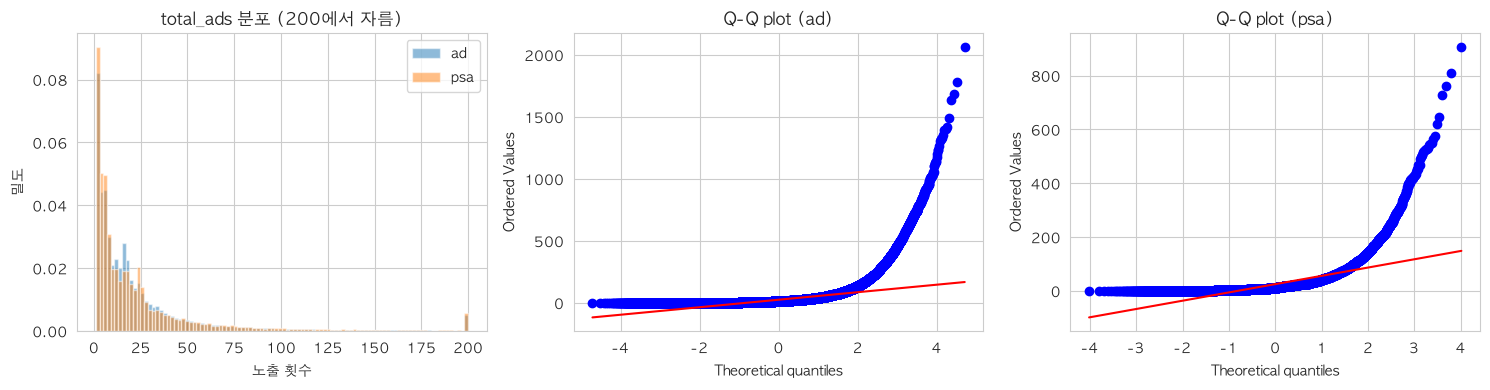

In [22]:
# ── 히스토그램 + Q-Q plot 으로 먼저 '눈으로' 확인 ─────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# (a) 원래 척도 히스토그램: 오른쪽 꼬리가 매우 긴지 확인
for g, color in [("ad", "C0"), ("psa", "C1")]:
    axes[0].hist(df.loc[df.group == g, "total_ads"].clip(upper=200), bins=100,
                 density=True, alpha=0.5, label=g, color=color)
axes[0].set(title="total_ads 분포 (200에서 자름)", xlabel="노출 횟수", ylabel="밀도")
axes[0].legend()

# (b), (c) 그룹별 Q-Q plot: 점이 직선을 벗어날수록 정규성 위반
for ax, g in zip(axes[1:], ["ad", "psa"]):
    stats.probplot(df.loc[df.group == g, "total_ads"], dist="norm", plot=ax)
    ax.set_title(f"Q-Q plot ({g})")
plt.tight_layout(); plt.show()

- **히스토그램(왼쪽):** 0 근처에 몰려 있고 오른쪽으로 꼬리가 길게 뻗음 → 종 모양(정규분포)이 아니다.
- **Q-Q plot(가운데·오른쪽):** 점이 빨간 직선 위에 있으면 정규분포. 오른쪽 위에서 점이 위로 크게 휘어 올라감 → **큰 값이 정규분포보다 훨씬 많다**
- 두 그룹의 모양은 거의 같다.

In [23]:
# ── Shapiro-Wilk: n > 5000 이면 p값이 부정확하므로 그룹별 5,000명 무작위 표본으로 수행 ──
for g in ["ad", "psa"]:
    sample = df.loc[df.group == g, "total_ads"].sample(5000, random_state=SEED)
    W, p = stats.shapiro(sample)
    print(f"Shapiro-Wilk ({g}, n=5000): W = {W:.4f}, p = {p:.2e}, 왜도 = {stats.skew(df.loc[df.group==g,'total_ads']):.2f}")

# ── Levene 등분산 검정 (중앙값 기준: 비정규 분포에 강건한 Brown-Forsythe 버전) ──
lev = stats.levene(df.loc[df.group == "ad", "total_ads"], df.loc[df.group == "psa", "total_ads"], center="median")
print(f"Levene (median): stat = {lev.statistic:.3f}, p = {lev.pvalue:.3f}")

Shapiro-Wilk (ad, n=5000): W = 0.5146, p = 1.64e-79, 왜도 = 7.50
Shapiro-Wilk (psa, n=5000): W = 0.5214, p = 3.33e-79, 왜도 = 5.65
Levene (median): stat = 5.358, p = 0.021


→ `total_ads`는 오른쪽으로 크게 치우친 분포(왜도 5~7, Shapiro p ≈ 0)로 정규성이 강하게 깨져 있고, Levene 검정(p ≈ 0.02)으로는 등분산도 의심된다.
- **Shapiro-Wilk** (귀무가설: "정규분포다")
  - p ≈ 0 → **정규분포가 아니다.** W는 1에 가까울수록 정규인데 0.51은 한참 멀다.
  - 표본이 5,000명을 넘으면 이 검정이 부정확해서 5,000명만 뽑아 검사진행.
- **왜도**: 0이면 좌우 대칭, 양수가 클수록 오른쪽 꼬리가 길다. 5~7은 **매우 치우침**.
- **Levene** (귀무가설: "두 그룹 분산이 같다")
  - p = 0.021 < 0.05 → 분산이 다르다고 볼 근거가 있다 (강하진 않음).
- 결론: 이 변수로 t-검정을 하면 가정이 깨짐 → Mann-Whitney U나 부트스트랩이 적합. **단, 우리 1차 지표는 비율(구매 여부)이라 상관없음**

---
# 4️⃣ 검정 수행하고 3종 세트로 보고

| 무엇을 | 보고 항목 |
|---|---|
| 얼마나 차이 나는가 | ① 점추정 (차이) |
| 그 추정이 얼마나 불확실한가 | ② 95% 신뢰구간 |
| 그 차이가 큰 차이인가 | ③ 효과 크기 |

비율 지표이므로 **절대 차이(%p)** 와 **상대 차이(배수)** 를 둘 다 기록필요.

## 4-1. 그룹별 전환율

In [24]:
# 그룹별 인원·전환 수·전환율
summary = df.groupby("group")["converted"].agg(n="count", conversions="sum", rate="mean")

# 그룹별 전환율의 95% 신뢰구간 (Wilson: 비율이 0이나 1에 가까울 때도 안정적)
ci = summary.apply(lambda r: proportion_confint(r.conversions, r.n, alpha=ALPHA, method="wilson"),
                   axis=1, result_type="expand")
summary["ci_low"], summary["ci_high"] = ci[0], ci[1]
summary

,n,conversions,rate,ci_low,ci_high
group,,,,,
ad,564577,14423,0.0255,0.0251,0.0260
psa,23524,420,0.0179,0.0162,0.0196


- 전환율: **ad 2.55% vs psa 1.79%**.
- `ci_low` ~ `ci_high` = **95% 신뢰구간**: "진짜 전환율이 이 범위 안에 있을 것"이라는 추정 범위.
  - Wilson: 비율의 신뢰구간을 구하는 계산 방법 중 하나.
- PSA 구간(1.62~1.96%)이 ad 구간(2.51~2.60%)보다 훨씬 넓음 → **인원이 적을수록 불확실성이 크다.**
- 두 구간이 겹치지 않음 → 차이가 있을 가능성이 높다는 힌트 (정식 판단은 4-2 검정으로).

findfont: Failed to find font weight bold for AppleGothic, now using 400.


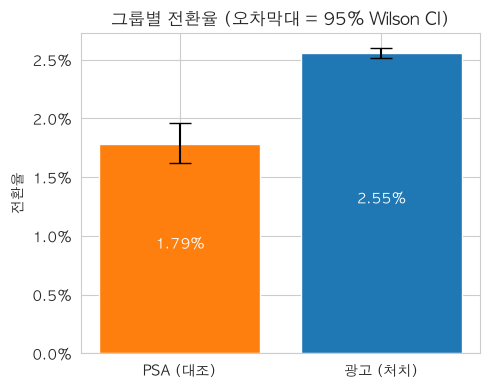

In [25]:
# 이후 계산에 쓸 변수 정리
x_ad,  n_ad  = int(summary.loc["ad",  "conversions"]), int(summary.loc["ad",  "n"])
x_psa, n_psa = int(summary.loc["psa", "conversions"]), int(summary.loc["psa", "n"])
p_ad, p_psa = x_ad / n_ad, x_psa / n_psa

# 전환율과 95% CI 시각화
fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["PSA (대조)", "광고 (처치)"], [p_psa, p_ad], color=["C1", "C0"],
       yerr=[[p_psa - summary.loc["psa", "ci_low"], p_ad - summary.loc["ad", "ci_low"]],
             [summary.loc["psa", "ci_high"] - p_psa, summary.loc["ad", "ci_high"] - p_ad]],
       capsize=8)
for i, v in enumerate([p_psa, p_ad]):
    ax.text(i, v / 2, f"{v:.2%}", ha="center", color="white", fontweight="bold")
ax.set(ylabel="전환율", title="그룹별 전환율 (오차막대 = 95% Wilson CI)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.1%}"))
plt.tight_layout(); plt.show()

- 막대 = 전환율, 막대 위 검은 선(오차막대) = 95% 신뢰구간.
- PSA 오차막대가 긴 것은 인원이 적어서 추정이 덜 정확하기 때문이다.
- 두 오차막대가 겹치지 않을 정도로 광고 쪽이 높다.

## 4-2. 검정 수행 — 카이제곱 독립성 검정 (+ 두 비율 z-검정 교차 확인)

In [26]:
# 2×2 분할표 (행: 그룹, 열: 전환 여부)
ct_main = pd.crosstab(df["group"], df["converted"])
print(ct_main, "\n")

# 주 결과: 연속성 보정 없음
chi2, p_chi, dof, _ = stats.chi2_contingency(ct_main, correction=False)
# 참고: Yates 연속성 보정
chi2_y, p_chi_y, _, _ = stats.chi2_contingency(ct_main, correction=True)
# 교차 확인: 두 비율 z-검정 (양측). z² 은 χ² 와 같아야 함
z, p_z = proportions_ztest([x_ad, x_psa], [n_ad, n_psa], alternative="two-sided")

print(f"카이제곱 (보정 없음) : χ²({dof}) = {chi2:.2f}, p = {p_chi:.3e}")
print(f"카이제곱 (Yates 보정): χ²({dof}) = {chi2_y:.2f}, p = {p_chi_y:.3e}")
print(f"두 비율 z-검정       : z = {z:.3f} (z² = {z**2:.2f}), p = {p_z:.3e}")
print(f"\n→ α = {ALPHA} 에서 H0 {'기각' if p_chi < ALPHA else '기각하지 못함'}")

converted   False  True 
group                   
ad         550154  14423
psa         23104    420 

카이제곱 (보정 없음) : χ²(1) = 54.32, p = 1.705e-13
카이제곱 (Yates 보정): χ²(1) = 54.01, p = 1.999e-13
두 비율 z-검정       : z = 7.370 (z² = 54.32), p = 1.705e-13

→ α = 0.05 에서 H0 기각


- 위 표: 실제 인원(관측도수). PSA 전환자는 **420명**으로, 효과가 없다면 예상되는 593.7명(3단계 기대도수)보다 훨씬 적다.
- **카이제곱 χ² = 54.32, p = 1.7e-13** (0.00000000000017)
  - "두 그룹 전환율이 정말 같다면, 이만큼 차이 날 확률이 사실상 0" → p < 0.05 → **H0 기각.**
- Yates 보정: 표본이 작을 때 쓰는 보수적 보정. 표본이 커서 결과가 거의 같다.
- 두 비율 z-검정: z² = 54.32 = χ² → **사실상 같은 검정**이라 p도 같다.
- ⚠️ 기각 = "차이가 있다". 차이가 **큰지·중요한지**는 다음 셀(효과 크기)과 5-D(비용)에서 따로 볼 것임.

## 4-3. 3종 세트 — 점추정 · 95% 신뢰구간 · 효과 크기

In [27]:
# ① 점추정
diff  = p_ad - p_psa          # 절대 차이 (비율 단위; ×100 하면 %p)
ratio = p_ad / p_psa          # 상대 차이 (배수)
lift  = ratio - 1             # 상대 상승률

# ② 95% 신뢰구간
#   - 절대 차이: Wald(비합동 분산)와 Newcombe(Wilson 기반, 더 정확) 두 방법
ci_diff_wald = confint_proportions_2indep(x_ad, n_ad, x_psa, n_psa, method="wald",    compare="diff", alpha=ALPHA)
ci_diff_newc = confint_proportions_2indep(x_ad, n_ad, x_psa, n_psa, method="newcomb", compare="diff", alpha=ALPHA)
#   - 상대 차이(위험비): 로그 변환 방법
ci_ratio     = confint_proportions_2indep(x_ad, n_ad, x_psa, n_psa, method="log",     compare="ratio", alpha=ALPHA)

# ③ 효과 크기
cramer_v = np.sqrt(chi2 / (ct_main.values.sum() * (min(ct_main.shape) - 1)))  # 2×2 에서는 |φ|
cohen_h  = proportion_effectsize(p_ad, p_psa)   # 2*arcsin(√p1) - 2*arcsin(√p2)

report = pd.DataFrame({
    "지표": ["전환율 ad", "전환율 psa", "① 절대 차이 (%p)", "① 상대 차이 (배수)", "① 상대 상승률",
             "② 95% CI 절대 차이 (Wald)", "② 95% CI 절대 차이 (Newcombe)", "② 95% CI 배수 (log)",
             "③ Cramér's V", "③ Cohen's h"],
    "값": [f"{p_ad:.3%}", f"{p_psa:.3%}", f"{diff*100:+.3f}%p", f"{ratio:.3f}배", f"{lift:+.1%}",
          f"[{ci_diff_wald[0]*100:.3f}, {ci_diff_wald[1]*100:.3f}]%p",
          f"[{ci_diff_newc[0]*100:.3f}, {ci_diff_newc[1]*100:.3f}]%p",
          f"[{ci_ratio[0]:.3f}, {ci_ratio[1]:.3f}]배",
          f"{cramer_v:.4f}", f"{cohen_h:.4f}"],
})
report

,지표,값
0,전환율 ad,2.555%
1,전환율 psa,1.785%
2,① 절대 차이 (%p),+0.769%p
3,① 상대 차이 (배수),1.431배
4,① 상대 상승률,+43.1%
5,② 95% CI 절대 차이 (Wald),"[0.595, 0.943]%p"
6,② 95% CI 절대 차이 (Newcombe),"[0.587, 0.936]%p"
7,② 95% CI 배수 (log),"[1.300, 1.575]배"
8,③ Cramér's V,0.0096
9,③ Cohen's h,0.0530


- **① 점추정**: 광고가 **+0.77%p** 높고, 상대적으로 **1.43배(+43%)**.
  - 전환율 자체가 2% 안팎으로 낮아서 %p로는 작아 보이고 배수로는 커 보인다 → 둘 다 기록.
- **② 95% 신뢰구간**: 진짜 차이는 **약 0.59~0.94%p**, 배수는 **1.30~1.58배** 사이일 것.
  - 구간 전체가 0(배수는 1)보다 큼 → "차이 없음"은 데이터와 맞지 않다.
  - Wald / Newcombe: 신뢰구간 계산 방법 두 가지. 결과가 거의 같으니 어느 쪽을 써도 결론은 같다.
- **③ 효과 크기**: 차이가 "얼마나 큰지"를 표준화한 숫자.
  - Cramér's V 0.0096 (작음 기준 0.1), Cohen's h 0.053 (작음 기준 0.2) → 둘 다 **"매우 작은" 효과**.
  - 하지만 이는 %p 차이 자체가 작아서이고, 상대적으로는 +43% 상승 (1.43배)입니다. **교훈:** 효과 크기 숫자만 보고 "의미 없다"고 하지 않는다.

In [28]:
# ── 안내문 형식의 보고 문장 자동 생성 ─────────────────────────────
p_str = "< .001" if p_chi < 0.001 else f"= {p_chi:.3f}".replace("0.", ".")
print(f"광고 그룹의 전환율이 더 높았다({p_ad:.2%} vs {p_psa:.2%}). "
      f"{diff*100:+.2f}%p [95% CI {ci_diff_newc[0]*100:.2f}–{ci_diff_newc[1]*100:.2f}%p], "
      f"상대적으로 {ratio:.2f}배({lift:+.0%}) [95% CI {ci_ratio[0]:.2f}–{ci_ratio[1]:.2f}배], "
      f"χ²({dof}) = {chi2:.2f}, p {p_str}, Cramér's V = {cramer_v:.3f}, Cohen's h = {cohen_h:.3f}")

광고 그룹의 전환율이 더 높았다(2.55% vs 1.79%). +0.77%p [95% CI 0.59–0.94%p], 상대적으로 1.43배(+43%) [95% CI 1.30–1.58배], χ²(1) = 54.32, p < .001, Cramér's V = 0.010, Cohen's h = 0.053


>  보고문장: 광고 그룹의 전환율이 더 높았다(2.55% vs 1.79%). +0.77%p [95% CI 0.59–0.94%p], 상대적으로 1.43배(+43%) [95% CI 1.30–1.58배], χ²(1) = 54.32, p < .001, Cramér's V = 0.010, Cohen's h = 0.05


- 읽는 순서: 전환율 비교 → 절대 차이[신뢰구간] → 상대 차이[신뢰구간] → 검정 통계량·p값 → 효과 크기.
- 이 한 문장에 "얼마나 차이 나나 / 얼마나 확실한가 / 얼마나 큰가"가 다 들어 있다.

In [29]:
# 요일별 2×2 표 만들기: [[ad 전환, ad 미전환], [psa 전환, psa 미전환]]
tables = []
for day, d in df.groupby("most_ads_day"):
    # 주의: .loc[..., [True, False]] 는 불리언 마스크로 해석되므로 reindex 로 열 순서를 지정
    t = pd.crosstab(d["group"], d["converted"]).reindex(index=["ad", "psa"], columns=[True, False]).values
    tables.append(t)

st = StratifiedTable(tables)
cmh = st.test_null_odds(correction=False)       # H0: 공통 오즈비 = 1
bd  = st.test_equal_odds()                      # Breslow-Day: 요일별 오즈비가 같은가 (이질성)
crude_or = (x_ad * (n_psa - x_psa)) / (x_psa * (n_ad - x_ad))   # 층화 안 한 오즈비

print(f"층화 전 오즈비 (crude)      : {crude_or:.3f}")
print(f"요일 층화 공통 오즈비 (MH)  : {st.oddsratio_pooled:.3f}, 95% CI {np.round(st.oddsratio_pooled_confint(), 3)}")
print(f"CMH 검정                    : χ² = {cmh.statistic:.2f}, p = {cmh.pvalue:.2e}")
print(f"Breslow-Day 이질성 검정     : χ² = {bd.statistic:.2f}, p = {bd.pvalue:.3f}")

층화 전 오즈비 (crude)      : 1.442
요일 층화 공통 오즈비 (MH)  : 1.439, 95% CI [1.305 1.587]
CMH 검정                    : χ² = 53.68, p = 2.35e-13
Breslow-Day 이질성 검정     : χ² = 16.09, p = 0.013


- **목적**: 1-4에서 요일마다 PSA 비율이 조금 달랐으니, **요일 영향을 걷어내도** 광고 효과가 그대로인지 확인해 본다. (요일별로 따로 비교한 뒤 합치는 방식)
- **오즈비**: 전환 "가능성"을 비교한 값. **1이면 차이 없음**, 1.44면 광고 그룹의 전환 가능성이 1.44배.
  - 전환율이 낮을 때는 배수(1.43)와 거의 같아집니다.
- 요일 통제 전 1.442 → 통제 후 1.439, **거의 그대로** → 요일 구성 차이가 결과를 만든 게 아니다.
- CMH p ≈ 0 → 요일을 통제해도 **여전히 유의**.
- Breslow-Day p = 0.013 → 요일마다 효과 크기가 다를 수 있다는 신호. 미리 정한 질문이 아니라서 참고만 하기.

→ 요일 구성을 통제해도 오즈비가 거의 그대로이고 여전히 유의합니다. **요일별 배정 비율의 작은 차이가 주 결론을 만든 것은 아닙니다.** (Breslow-Day 결과는 요일별로 효과 크기가 다른지에 대한 탐색 정보일 뿐, 사전 지정 가설이 아닙니다.)

---
# 5️⃣ 한 걸음 더

## 5-A. 이 실험은 효과를 잡을 '힘'이 있었나

- 기저 전환율($p_0$)은 PSA 그룹 전환율을 사용합니다. (실무에서는 실험 **전** 과거 데이터로 정하는 값입니다.)
- 비율 효과 크기는 Cohen's h를 쓰고, `NormalIndPower`로 계산합니다.
- ⚠️ **사후 검정력(관측된 효과로 계산한 power)은 구하지 않습니다.** 관측 p값을 다시 쓴 것에 불과하기 때문입니다. 대신 **"이 표본으로 잡을 수 있었던 최소 효과(MDE)"** 를 구합니다.

### (1) 80% 검정력으로 +1%p를 잡으려면 그룹당 몇 명?

In [30]:
power_analysis = NormalIndPower()
p0 = p_psa                       # 기저 전환율
target_pp = 0.01                 # 잡고 싶은 효과: +1%p
h_target = proportion_effectsize(p0 + target_pp, p0)   # Cohen's h (양수)

# (a) 50:50 설계라면 그룹당 필요 인원
n_equal = power_analysis.solve_power(effect_size=h_target, alpha=ALPHA, power=0.8,
                                     ratio=1, alternative="two-sided")

# (b) 실제와 같은 96:4 설계라면 — nobs1 = PSA 인원, ratio = ad/psa
ratio_actual = n_ad / n_psa
n_psa_need = power_analysis.solve_power(effect_size=h_target, alpha=ALPHA, power=0.8,
                                        ratio=ratio_actual, alternative="two-sided")

print(f"기저 전환율 p0 = {p0:.3%} → 목표 {p0+target_pp:.3%} (+1%p), Cohen's h = {h_target:.4f}")
print(f"(a) 50:50 설계 : 그룹당 {np.ceil(n_equal):,.0f} 명 (총 {2*np.ceil(n_equal):,.0f} 명)")
print(f"(b) 96:4 설계  : PSA {np.ceil(n_psa_need):,.0f} 명 + ad {np.ceil(n_psa_need*ratio_actual):,.0f} 명 "
      f"(총 {np.ceil(n_psa_need)*(1+ratio_actual):,.0f} 명)")
print(f"실제 표본      : PSA {n_psa:,} 명 + ad {n_ad:,} 명 (총 {n_ad+n_psa:,} 명)")

기저 전환율 p0 = 1.785% → 목표 2.785% (+1%p), Cohen's h = 0.0673
(a) 50:50 설계 : 그룹당 3,464 명 (총 6,928 명)
(b) 96:4 설계  : PSA 1,805 명 + ad 43,297 명 (총 45,125 명)
실제 표본      : PSA 23,524 명 + ad 564,577 명 (총 588,101 명)


- **검정력 80%** = "진짜 효과가 있을 때 그걸 잡아낼 확률이 80%".
- +1%p 효과를 잡으려면
  - 50:50 설계: 그룹당 **3,464명** (총 6,928명)
  - 96:4 설계: 총 **45,125명** → 같은 효과를 잡는 데 **약 6.5배 많은 인원**이 필요. 그룹 크기가 불균형하면 비효율적입니다.
- 실제 표본(PSA 23,524명)은 필요 인원(1,805명)보다 훨씬 많음 → +1%p 정도는 충분히 잡을 수 있는 실험이었습니다.

### (2) MDE — 지금 표본으로 잡을 수 있는 가장 작은 효과
`solve_power()`에 `nobs1=`(PSA 인원)과 `ratio=`(ad/psa)를 주고 `effect_size`를 비워서 풉니다. 나온 Cohen's h를 다시 전환율로 되돌립니다:
$h = 2\arcsin\sqrt{p_1} - 2\arcsin\sqrt{p_0} \;\Rightarrow\; p_1 = \sin^2\!\left(\arcsin\sqrt{p_0} + h/2\right)$

In [31]:
def h_to_p1(h, p0):
    # Cohen's h 를 처치군 전환율 p1 로 역변환
    return np.sin(np.arcsin(np.sqrt(p0)) + h / 2) ** 2

# 실제 표본(96:4)의 MDE
h_mde = power_analysis.solve_power(effect_size=None, nobs1=n_psa, alpha=ALPHA, power=0.8,
                                   ratio=ratio_actual, alternative="two-sided")
mde_pp = h_to_p1(h_mde, p0) - p0

# 교차 확인: 정규근사 공식 MDE ≈ (z_{1-α/2} + z_{0.8}) * sqrt(p0(1-p0)(1/n1 + 1/n2))
z_a, z_b = stats.norm.ppf(1 - ALPHA / 2), stats.norm.ppf(0.8)
mde_formula = (z_a + z_b) * np.sqrt(p0 * (1 - p0) * (1 / n_psa + 1 / n_ad))

# 비교: 같은 총인원을 50:50 으로 나눴다면?
h_mde_eq = power_analysis.solve_power(effect_size=None, nobs1=(n_ad + n_psa) / 2, alpha=ALPHA,
                                      power=0.8, ratio=1, alternative="two-sided")
mde_eq_pp = h_to_p1(h_mde_eq, p0) - p0

print(f"MDE (실제 96:4, solve_power) : {mde_pp*100:.3f}%p  (상대 {mde_pp/p0:.1%})")
print(f"MDE (정규근사 공식, 교차확인): {mde_formula*100:.3f}%p")
print(f"MDE (같은 총인원 50:50 가정) : {mde_eq_pp*100:.3f}%p")
print(f"관측된 차이                  : {diff*100:.3f}%p")

MDE (실제 96:4, solve_power) : 0.255%p  (상대 14.3%)
MDE (정규근사 공식, 교차확인): 0.247%p
MDE (같은 총인원 50:50 가정) : 0.098%p
관측된 차이                  : 0.769%p


- **MDE(최소 검출 효과)** = 이 표본으로 80% 확률로 잡을 수 있는 **가장 작은 효과**.
- 실제 설계의 MDE ≈ **0.26%p**. 공식으로 다시 계산해도 0.25%p로 일치합니다.
- 관측된 차이 0.77%p는 MDE의 약 3배 → **잡기에 충분히 큰 효과**였습니다.
- 같은 인원을 50:50으로 나눴다면 MDE 0.10%p → 훨씬 작은 효과까지 잡을 수 있었습니다.
- 의미: 진짜 효과가 0.1%p 정도였다면 이 실험은 놓쳤을 것 → **"유의하지 않음 ≠ 효과 없음"**.

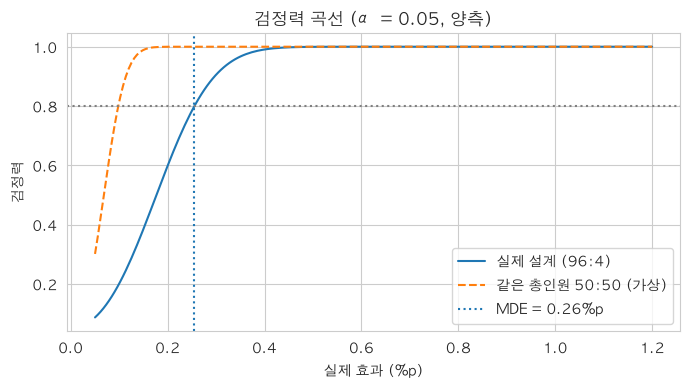

In [32]:
# ── 검정력 곡선: 실제 표본에서 효과 크기(%p)별로 잡을 확률 ───────────
effects_pp = np.linspace(0.0005, 0.012, 200)
powers = [power_analysis.power(effect_size=proportion_effectsize(p0 + e, p0), nobs1=n_psa,
                               alpha=ALPHA, ratio=ratio_actual) for e in effects_pp]
powers_eq = [power_analysis.power(effect_size=proportion_effectsize(p0 + e, p0), nobs1=(n_ad + n_psa) / 2,
                                  alpha=ALPHA, ratio=1) for e in effects_pp]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(effects_pp * 100, powers, label="실제 설계 (96:4)")
ax.plot(effects_pp * 100, powers_eq, ls="--", label="같은 총인원 50:50 (가상)")
ax.axhline(0.8, color="gray", ls=":")
ax.axvline(mde_pp * 100, color="C0", ls=":", label=f"MDE = {mde_pp*100:.2f}%p")
ax.set(xlabel="실제 효과 (%p)", ylabel="검정력", title="검정력 곡선 (α = 0.05, 양측)")
ax.legend(); plt.tight_layout(); plt.show()

- 가로축 = 진짜 효과 크기(%p), 세로축 = 그 효과를 잡아낼 확률(검정력).
- 회색 점선(80%)과 실선이 만나는 지점 = MDE(파란 점선, 약 0.26%p).
- 점선(50:50)이 실선(96:4)보다 왼쪽에서 먼저 올라감 → **균형 설계가 작은 효과를 더 잘 잡는 걸 볼 수 있다.**

**결론 (5-A)**
- 이 실험의 MDE는 약 **0.26%p**(상대 약 14%)입니다 → **"우리 표본은 약 0.26%p 이상의 효과만 80% 확률로 볼 수 있었다."**
- 관측 효과(약 0.77%p)는 MDE의 3배 정도라, 이 실험은 이 정도 효과를 잡기에 충분한 힘이 있었다.
- 반대로 진짜 효과가 0.1~0.2%p 수준이었다면 이 설계로는 놓쳤을 가능성이 큽니다. 그 경우 "유의하지 않음"은 "효과 없음"이 아니라 "**확인할 힘이 없었음**"으로 읽어야 한다.
- 96:4 불균형 설계의 대가: 같은 총인원을 50:50으로 나눴다면 MDE가 약 0.10%p로 2.5배 이상 작았을 것입니다. 검정력은 **작은 쪽 그룹(PSA) 크기**에 거의 좌우된다.

---
## 5-B. 가정이 깨졌다면

1차 지표(전환)는 비율이라 정규성 문제가 없지만, 연속형인 `total_ads`(노출 횟수)는 3단계에서 본 것처럼 정규성이 크게 깨져 있습니다. 이 변수로 **t-검정 / Mann-Whitney U / 부트스트랩** 결과를 비교한다.
`total_ads`는 "광고(또는 PSA)를 얼마나 봤는가"이므로, 두 그룹 노출량이 비슷했는지 보는 **가드레일 지표** 역할도 한다.

### (1) 분포 진단 — 히스토그램 · 박스플롯 · 이상치

             count    mean     std    min    25%     50%     75%      99%  \
group                                                                       
ad    564,577.0000 24.8000 43.8000 1.0000 4.0000 13.0000 27.0000 201.0000   
psa    23,524.0000 24.8000 42.9000 1.0000 4.0000 12.0000 26.0000 206.0000   

             max  
group             
ad    2,065.0000  
psa     907.0000  


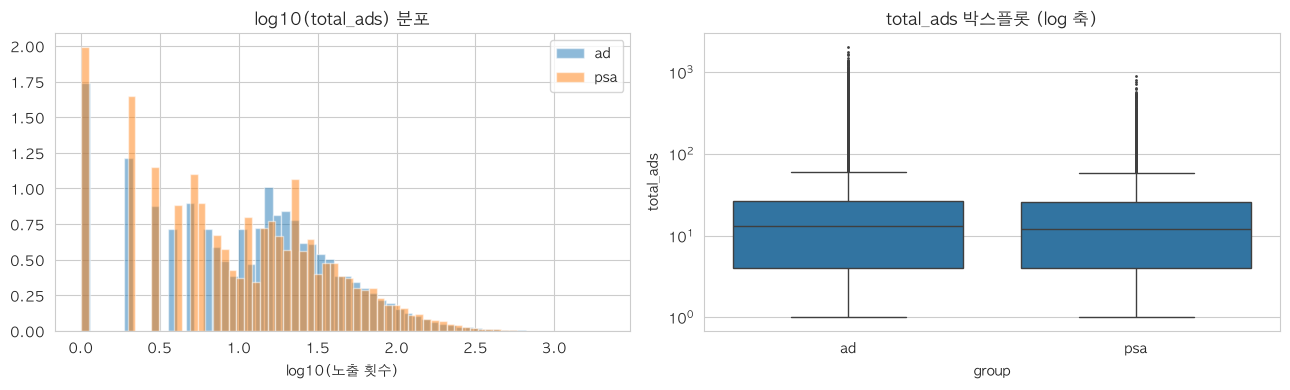

In [33]:
ad_ads  = df.loc[df.group == "ad",  "total_ads"].values
psa_ads = df.loc[df.group == "psa", "total_ads"].values

# 그룹별 요약: 평균과 중앙값 차이, 왜도
print(df.groupby("group")["total_ads"].describe(percentiles=[.25, .5, .75, .99]).round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
# (a) 로그 척도 히스토그램: 오른쪽 꼬리 구조를 보기 위해 log10 변환
for g, arr in [("ad", ad_ads), ("psa", psa_ads)]:
    axes[0].hist(np.log10(arr), bins=60, density=True, alpha=0.5, label=g)
axes[0].set(title="log10(total_ads) 분포", xlabel="log10(노출 횟수)"); axes[0].legend()
# (b) 박스플롯 (로그 y축): 이상치가 얼마나 멀리 있는지
sns.boxplot(data=df, x="group", y="total_ads", ax=axes[1], fliersize=1)
axes[1].set_yscale("log"); axes[1].set_title("total_ads 박스플롯 (log 축)")
plt.tight_layout(); plt.show()

- 두 그룹 노출 횟수가 **거의 같다**: 평균 24.8 vs 24.8, 중앙값 13 vs 12, 상위 1% 201 vs 206.
  - → 광고 그룹이 "더 많이 노출돼서" 전환율이 높은 게 아니라는 점이 확인(가드레일)이 된다.
- 최댓값(2,065 vs 907)이 다른 건 ad 그룹 인원이 24배 많아 극단값이 나올 기회가 많아서이다.
- **log 히스토그램(왼쪽)**: 로그로 바꾸면 긴 꼬리가 펴져서 보기 쉬움. 두 그룹 분포가 거의 잡힌다.
- **박스플롯(오른쪽)**: 상자 = 가운데 50%, 위쪽 점들 = 이상치. 이상치가 매우 많다.

In [34]:
# IQR 규칙으로 이상치 경계 계산 (전체 데이터 기준 하나의 경계 사용)
q1, q3 = np.percentile(df["total_ads"], [25, 75])
upper = q3 + 1.5 * (q3 - q1)
is_out = df["total_ads"] > upper
print(f"IQR 상한 = {upper:.1f}회 → 이상치 {is_out.sum():,}명 ({is_out.mean():.2%})")
print(df.assign(outlier=is_out).groupby("group")["outlier"].mean().map("{:.2%}".format))

IQR 상한 = 61.5회 → 이상치 52,057명 (8.85%)
group
ad     8.83%
psa    9.34%
Name: outlier, dtype: object


- **IQR 규칙**: IQR = 3사분위(27) − 1사분위(4) = 23. 상한 = 27 + 1.5 × 23 = **61.5회**.
- 62회 이상 본 사람 = 이상치 **52,057명(8.85%)**.
- 그룹별 이상치 비율도 비슷(8.83% vs 9.34%) → 한쪽 그룹에 몰려 있지 않습니다.


### (2) t-검정 vs Mann-Whitney U vs 부트스트랩

In [35]:
# Welch t-검정: 평균 비교 (등분산 가정 X). 표본이 커서 CLT 덕에 평균 비교 자체는 유효
t_res = stats.ttest_ind(ad_ads, psa_ads, equal_var=False)

# Mann-Whitney U: 분포 위치(한 그룹 값이 다른 그룹보다 큰 경향) 비교, 정규성 가정 X
mw_res = stats.mannwhitneyu(ad_ads, psa_ads, alternative="two-sided")
cles = mw_res.statistic / (len(ad_ads) * len(psa_ads))   # P(ad 값 > psa 값): 0.5면 차이 없음
rank_biserial = 2 * cles - 1                              # 효과 크기 (-1 ~ 1)

# 효과 크기: Cohen's d (합동 표준편차)
sp = np.sqrt(((len(ad_ads) - 1) * ad_ads.var(ddof=1) + (len(psa_ads) - 1) * psa_ads.var(ddof=1))
             / (len(ad_ads) + len(psa_ads) - 2))
cohen_d = (ad_ads.mean() - psa_ads.mean()) / sp

print(f"평균 차이  = {ad_ads.mean() - psa_ads.mean():.3f}회 | 중앙값 차이 = {np.median(ad_ads) - np.median(psa_ads):.1f}회")
print(f"Welch t    : t = {t_res.statistic:.3f}, p = {t_res.pvalue:.3f}, Cohen's d = {cohen_d:.4f}")
print(f"Mann-Whitney U: p = {mw_res.pvalue:.2e}, P(ad > psa) = {cles:.4f}, rank-biserial r = {rank_biserial:.4f}")

평균 차이  = 0.062회 | 중앙값 차이 = 1.0회
Welch t    : t = 0.218, p = 0.827, Cohen's d = 0.0014
Mann-Whitney U: p = 4.69e-11, P(ad > psa) = 0.5126, rank-biserial r = 0.0253


- 평균 차이 0.06회, 중앙값 차이 1회 → 숫자로만 봐도 거의 같다.
- **Welch t-검정** (평균 비교): p = 0.83 → **평균은 차이 없음**. Cohen's d 0.0014 ≈ 0.
- **Mann-Whitney U** (순위 비교): p ≈ 0 → "다르다"고 나옴. 그런데
  - P(ad > psa) = 0.51: 두 그룹에서 한 명씩 뽑아 비교하면 ad가 더 클 확률 51%. **50%면 완전히 같은 것** → 실질적으로 차이 없음.
  - rank-biserial r 0.025 (0이면 차이 없음) → 미미.
- 교훈: 두 검정은 묻는 질문이 다릅니다(평균 vs 분포 전체의 위치). 그리고 **표본이 크면 의미 없는 차이도 p가 작게 나온다** → 효과 크기를 꼭 같이 봐야함.

In [36]:
# ── 부트스트랩 신뢰구간 (그룹별로 따로 복원추출, B = 1,000, 시드 고정) ──
B = 1000
boot_rng = np.random.default_rng(SEED)
boot_mean_diff, boot_median_diff = np.empty(B), np.empty(B)
for b in range(B):
    s_ad  = ad_ads[boot_rng.integers(0, len(ad_ads),  len(ad_ads))]
    s_psa = psa_ads[boot_rng.integers(0, len(psa_ads), len(psa_ads))]
    boot_mean_diff[b]   = s_ad.mean() - s_psa.mean()
    boot_median_diff[b] = np.median(s_ad) - np.median(s_psa)

ci_mean_boot   = np.percentile(boot_mean_diff,   [2.5, 97.5])
ci_median_boot = np.percentile(boot_median_diff, [2.5, 97.5])
ci_mean_t = (ad_ads.mean() - psa_ads.mean()) + np.array([-1, 1]) * stats.norm.ppf(0.975) * \
            np.sqrt(ad_ads.var(ddof=1) / len(ad_ads) + psa_ads.var(ddof=1) / len(psa_ads))

print(f"평균 차이 95% CI (Welch 정규근사): [{ci_mean_t[0]:.3f}, {ci_mean_t[1]:.3f}]")
print(f"평균 차이 95% CI (부트스트랩)    : [{ci_mean_boot[0]:.3f}, {ci_mean_boot[1]:.3f}]")
print(f"중앙값 차이 95% CI (부트스트랩)  : [{ci_median_boot[0]:.1f}, {ci_median_boot[1]:.1f}]")

평균 차이 95% CI (Welch 정규근사): [-0.497, 0.622]
평균 차이 95% CI (부트스트랩)    : [-0.498, 0.607]
중앙값 차이 95% CI (부트스트랩)  : [1.0, 2.0]


- **부트스트랩** = 내 데이터에서 무작위로 다시 뽑기를 1,000번 반복해, 결과가 얼마나 흔들리는지 보는 방법. 정규분포 가정이 필요 없다.
- 평균 차이 신뢰구간: 일반 방법 [−0.50, 0.62] ≈ 부트스트랩 [−0.50, 0.61]
  - **0을 포함** → 평균 차이 없음.
  - 두 방법이 거의 같음 → 표본이 크면 분포가 치우쳐도 평균에 대한 일반 방법이 잘 맞다 (중심극한정리).
- 중앙값 차이 신뢰구간 [1, 2]회 → 0을 포함하지 않아 중앙값은 ad가 1~2회 많음. 하지만 **1~2회는 실질적 의미가 거의 없는** 차이이다.

In [37]:
# ── 1차 지표(전환율 차이)도 부트스트랩으로 교차 확인 ─────────────────
# 0/1 데이터의 복원추출은 '이항분포에서 전환 수를 뽑는 것'과 같으므로 빠르게 계산 가능
B_conv = 10000
conv_rng = np.random.default_rng(SEED)
boot_conv_diff = conv_rng.binomial(n_ad, p_ad, B_conv) / n_ad - conv_rng.binomial(n_psa, p_psa, B_conv) / n_psa
ci_conv_boot = np.percentile(boot_conv_diff, [2.5, 97.5])
print(f"전환율 차이 95% CI — 부트스트랩: [{ci_conv_boot[0]*100:.3f}, {ci_conv_boot[1]*100:.3f}]%p")
print(f"전환율 차이 95% CI — Wald      : [{ci_diff_wald[0]*100:.3f}, {ci_diff_wald[1]*100:.3f}]%p")

전환율 차이 95% CI — 부트스트랩: [0.597, 0.942]%p
전환율 차이 95% CI — Wald      : [0.595, 0.943]%p


- 1차 지표인 **전환율 차이**도 부트스트랩으로 확인: [0.596, 0.939]%p vs 4-3의 Wald [0.595, 0.943]%p.
- 거의 같음 → **4-3의 신뢰구간을 믿을 수 있습니다.**

### (3) 이상치를 빼기 전과 후 — 결론이 바뀌는가?

In [38]:
# IQR 상한을 넘는 사용자를 뺀 데이터로 같은 분석 반복
df_trim = df[~is_out]
rows = []
for label, d in [("전체", df), (f"이상치 제거 (total_ads ≤ {upper:.0f})", df_trim)]:
    a = d.loc[d.group == "ad", "total_ads"]; p = d.loc[d.group == "psa", "total_ads"]
    ct = pd.crosstab(d["group"], d["converted"])
    c2, pc, _, _ = stats.chi2_contingency(ct, correction=False)
    ra, rp = d.loc[d.group == "ad", "converted"].mean(), d.loc[d.group == "psa", "converted"].mean()
    rows.append({
        "데이터": label, "n": len(d),
        "total_ads 평균 ad": a.mean(), "total_ads 평균 psa": p.mean(),
        "total_ads Welch p": stats.ttest_ind(a, p, equal_var=False).pvalue,
        "total_ads MWU p": stats.mannwhitneyu(a, p).pvalue,
        "전환율 ad": ra, "전환율 psa": rp, "차이(%p)": (ra - rp) * 100,
        "배수": ra / rp, "전환 χ² p": pc,
    })
pd.DataFrame(rows).set_index("데이터").T

데이터,전체,이상치 제거 (total_ads ≤ 62)
n,"588,101.0000","536,044.0000"
total_ads 평균 ad,24.8234,15.1598
total_ads 평균 psa,24.7611,14.5118
total_ads Welch p,0.8274,0.0000
total_ads MWU p,0.0000,0.0000
전환율 ad,0.0255,0.0134
전환율 psa,0.0179,0.0106
차이(%p),0.7692,0.2788
배수,1.4309,1.2631
전환 χ² p,0.0000,0.0005


- 이상치(62회 이상)를 빼면 536,044명이 남는다.
- **전환율 자체가 거의 절반으로** 떨어짐 (ad 2.55→1.34%, psa 1.79→1.06%) → 많이 본 사람일수록 구매도 많이 했다는 뜻.
- 광고 효과: 차이 **0.77 → 0.28%p**, 배수 **1.43 → 1.26배** → 효과 크기가 약 1/3로 줄어듭니다.
- 그래도 전환 χ² p = 0.0005 < 0.05 → **"광고가 더 높다"는 방향과 유의성은 유지.**
- 이상치를 빼니 `total_ads` 평균 차이도 유의(p ≈ 0)해졌지만, 15.16 vs 14.51로 **1회도 안 되는 차이**라 의미 없다.
- 정리: 광고 효과의 상당 부분이 **많이 노출된 사람에게서** 나온다. 단, 노출 횟수는 실험 후에 측정된 값이라 "노출을 늘리면 효과가 커진다"는 인과 결론은 낼 수 없다.

**결론 (5-B)**
- **세 방법이 서로 다른 질문에 답합니다.** Welch t와 부트스트랩(평균)은 "평균 노출 수가 같은가?" → 차이 없음. Mann-Whitney U는 "한 그룹 값이 전반적으로 더 큰가?" → 표본이 매우 커서 p는 아주 작지만, P(ad > psa) ≈ 0.51로 **실질적으로 무시할 만한** 차이입니다. p값만 보고 "노출량이 다르다"고 결론 내리면 안 되는 좋은 예입니다.
- 부트스트랩 CI는 정규근사 CI와 거의 일치 → 표본이 이 정도로 크면 평균 비교의 정규근사는 왜도가 커도 잘 작동합니다.
- 1차 지표인 전환율 차이도 부트스트랩 CI가 Wald CI와 거의 같습니다.
- **이상치 제거 전후 — 방향·유의성은 유지되지만 크기는 크게 바뀝니다.**
  - 고노출 사용자(상위 약 9%)를 빼면 두 그룹 전환율 자체가 거의 절반으로 떨어지고, 차이는 **+0.77%p → +0.28%p**, 배수는 **1.43 → 1.26배**로 줄어듭니다. 그래도 p < .001로 "광고 > PSA"라는 결론은 유지됩니다.
  - 즉 **광고 효과의 상당 부분이 많이 노출된 사용자에게서 나옵니다** (효과의 이질성). 단, `total_ads`는 배정 이후 관측된 변수라 "노출을 늘리면 효과가 커진다"는 인과 주장은 할 수 없습니다.
  - 제거 후에는 `total_ads` 평균 차이도 유의해지지만, 평균 차이가 1회 미만이라 실질적 의미는 없습니다 (표본이 크면 작은 차이도 유의).
  - **판단:** 고노출 사용자는 오류가 아니라 실제 고객이며, 출시하면 이들에게도 광고가 나갑니다. 그래서 **전체 데이터 분석을 주 결과로 유지**합니다. 대신 "고노출 사용자를 빼면 효과가 약 1/3로 줄어든다"는 사실을 결과와 한계에 함께 적고, 5-D에서 이 경우의 손익도 따로 계산합니다.

---
## 5-C. 유의한 결과는 '만들어질' 수 있다

### (1) 실제 데이터: 요일(7) + 시간대(24) = 31개 세그먼트로 쪼개 검정 반복
세그먼트마다 ad vs psa 전환율을 검정합니다. 기대도수가 5 미만인 작은 세그먼트는 Fisher 정확검정을 씁니다.

In [39]:
def segment_tests(data, col):
    # col 의 각 값(세그먼트)별로 ad vs psa 전환율 차이 검정
    out = []
    for level, d in data.groupby(col):
        ct = pd.crosstab(d["group"], d["converted"]).reindex(index=["ad", "psa"], columns=[True, False], fill_value=0)
        exp = stats.chi2_contingency(ct, correction=False)[3]
        if exp.min() < 5:                       # 작은 칸 → Fisher 정확검정
            p = stats.fisher_exact(ct.values)[1]; method = "Fisher"
        else:
            p = stats.chi2_contingency(ct, correction=False)[1]; method = "χ²"
        ra = ct.loc["ad", True] / ct.loc["ad"].sum(); rp = ct.loc["psa", True] / ct.loc["psa"].sum()
        out.append({"세그먼트": f"{col}={level}", "n_psa": ct.loc["psa"].sum(),
                    "ad": ra, "psa": rp, "차이(%p)": (ra - rp) * 100, "검정": method, "p": p})
    return out

seg = pd.DataFrame(segment_tests(df, "most_ads_day") + segment_tests(df, "most_ads_hour"))

# 다중검정 보정: Bonferroni (FWER 통제), Benjamini-Hochberg (FDR 통제)
seg["p_bonf"] = multipletests(seg["p"], alpha=ALPHA, method="bonferroni")[1]
seg["p_bh"]   = multipletests(seg["p"], alpha=ALPHA, method="fdr_bh")[1]

print(f"검정 개수: {len(seg)}")
print(f"보정 전  p < {ALPHA}: {(seg.p < ALPHA).sum()}개")
print(f"Bonferroni 후      : {(seg.p_bonf < ALPHA).sum()}개")
print(f"BH(FDR) 후         : {(seg.p_bh < ALPHA).sum()}개")
seg.sort_values("p").head(12)

검정 개수: 31
보정 전  p < 0.05: 13개
Bonferroni 후      : 4개
BH(FDR) 후         : 5개


,세그먼트,n_psa,ad,psa,차이(%p),검정,p,p_bonf,p_bh
5,most_ads_day=Tuesday,2907,0.0304,0.0144,1.5992,χ²,0.0000,0.0000,0.0000
6,most_ads_day=Wednesday,3490,0.0254,0.0158,0.9597,χ²,0.0004,0.0117,0.0052
1,most_ads_day=Monday,3502,0.0332,0.0226,1.0683,χ²,0.0005,0.0157,0.0052
21,most_ads_hour=14,1869,0.0286,0.0161,1.2524,χ²,0.0013,0.0411,0.0103
2,most_ads_day=Saturday,2858,0.0213,0.0140,0.7311,χ²,0.0075,0.2320,0.0464
0,most_ads_day=Friday,3803,0.0225,0.0163,0.6162,χ²,0.0116,0.3586,0.0573
20,most_ads_hour=13,2170,0.0251,0.0166,0.8473,χ²,0.0129,0.4009,0.0573
27,most_ads_hour=20,1077,0.0303,0.0176,1.2632,χ²,0.0168,0.5193,0.0584
18,most_ads_hour=11,2061,0.0225,0.0146,0.7913,χ²,0.0170,0.5255,0.0584
7,most_ads_hour=0,227,0.0192,0.0000,1.9213,Fisher,0.0220,0.6826,0.0683


- 요일 7개 + 시간대 24개 = **31개 세그먼트**마다 광고 효과를 따로 검정했습니다.
- p < 0.05인 세그먼트: **보정 전 13개 → Bonferroni 4개, BH 5개**.
- **다중검정 보정**: 검정을 여러 번 하면 우연히 "유의"가 나올 확률이 커지므로 기준을 엄격하게 바꾸는 것.
  - Bonferroni: p값에 검정 횟수(31)를 곱함 → **가장 엄격**.
  - BH: 덜 엄격. "유의하다고 판정한 것 중 가짜 비율"을 5% 이하로 맞춥니다.
  - 표의 `p_bonf`, `p_bh`가 보정 후 p값 → 이 값이 0.05보다 작아야 유의.
- `Fisher`: 새벽 0시는 PSA가 227명뿐이라 기대도수 5 미만 → 정확검정을 사용.
- 유의하지 않은 세그먼트도 대부분 차이는 양수 → 효과가 없어서라기보다 **세그먼트당 인원이 적어서** 못 잡은 것.

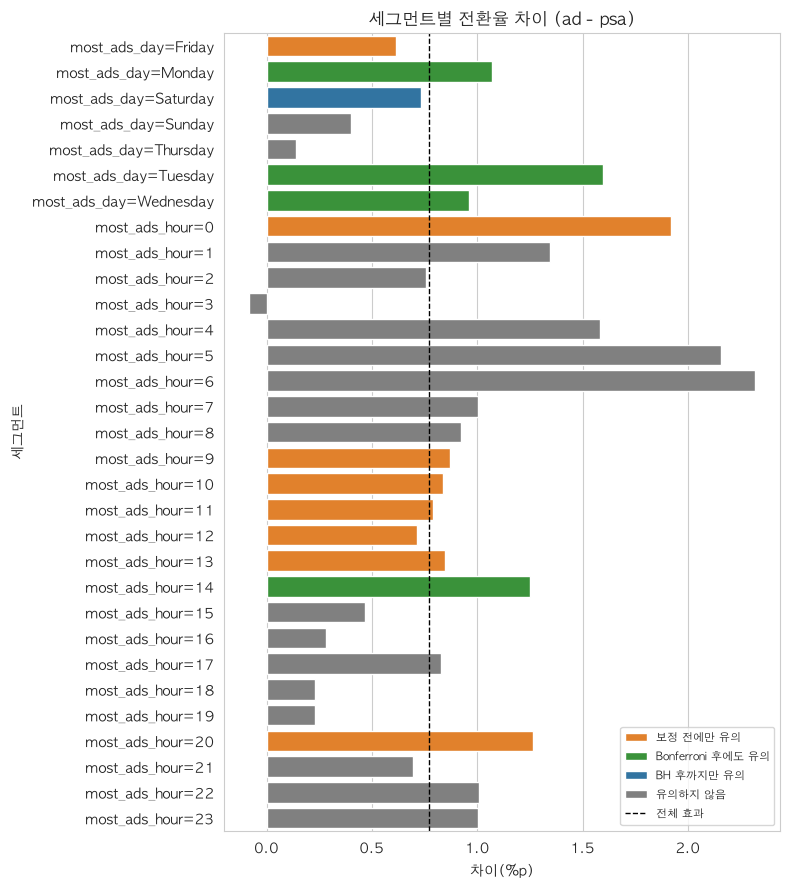

In [47]:
# ── 세그먼트별 차이 시각화: 보정 전/후 유의 여부를 색으로 구분 ────────
seg["상태"] = np.select([seg.p_bonf < ALPHA, seg.p_bh < ALPHA, seg.p < ALPHA],
                       ["Bonferroni 후에도 유의", "BH 후까지만 유의", "보정 전에만 유의"], "유의하지 않음")
fig, ax = plt.subplots(figsize=(8, 9))
palette = {"Bonferroni 후에도 유의": "C2", "BH 후까지만 유의": "C0", "보정 전에만 유의": "C1", "유의하지 않음": "gray"}
sns.barplot(data=seg, y="세그먼트", x="차이(%p)", hue="상태", dodge=False, palette=palette, ax=ax)
ax.axvline(diff * 100, color="k", ls="--", lw=1, label="전체 효과")
ax.set_title("세그먼트별 전환율 차이 (ad - psa)"); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

- 막대 = 세그먼트별 광고 효과(%p), 색 = 보정 후 유의 여부, 검은 점선 = 전체 효과(0.77%p).
- 막대들이 대체로 점선 주변에 흩어져 있음 → 세그먼트별 차이는 상당 부분 **우연한 흔들림**일 수 있다.
- 새벽 시간대(4~6시)는 막대가 길지만 회색 → 인원이 적어 들쭉날쭉한 것이지 진짜 효과가 크다는 뜻이 아님.


### (2) A/A 시뮬레이션: 효과가 0인데도 '유의한 세그먼트'가 나오는가?
광고 그룹 **내부**만 사용해(모두 같은 처치를 받음) 무작위로 가짜 A/B 라벨을 붙이고, 같은 31개 세그먼트 검정을 500번 반복합니다. 여기서 나오는 유의한 결과는 **전부 거짓 양성**입니다.

In [41]:
# 광고 그룹 내부 데이터만 사용 → 진짜 효과는 정의상 0
aa = df[df.group == "ad"].reset_index(drop=True)
conv = aa["converted"].values.astype(float)
codes = [pd.factorize(aa["most_ads_day"])[0], aa["most_ads_hour"].values]   # 7개 + 24개 세그먼트
n_tests = sum(len(np.unique(c)) for c in codes)

def seg_pvalues(fake):
    # 가짜 라벨(fake: True/False)로 세그먼트별 두 비율 z-검정 p값을 벡터화해 계산
    pv = []
    for c in codes:
        K = c.max() + 1
        key = c * 2 + fake                                      # (세그먼트, 라벨) 조합 번호
        n = np.bincount(key, minlength=2 * K).reshape(K, 2)     # 조합별 인원
        x = np.bincount(key, weights=conv, minlength=2 * K).reshape(K, 2)  # 조합별 전환 수
        p1, p2 = x[:, 1] / n[:, 1], x[:, 0] / n[:, 0]
        pp = x.sum(1) / n.sum(1)                                # 합동 비율
        se = np.sqrt(pp * (1 - pp) * (1 / n[:, 0] + 1 / n[:, 1]))
        pv.append(2 * stats.norm.sf(np.abs((p1 - p2) / se)))
    return np.concatenate(pv)

n_sim = 500
sim_rng = np.random.default_rng(SEED)
res = {"보정 전": [], "Bonferroni": [], "BH": []}
for _ in range(n_sim):
    fake = (sim_rng.random(len(aa)) < 0.5).astype(int)          # 50:50 가짜 라벨
    pv = seg_pvalues(fake)
    res["보정 전"].append((pv < ALPHA).sum())
    res["Bonferroni"].append(multipletests(pv, alpha=ALPHA, method="bonferroni")[0].sum())
    res["BH"].append(multipletests(pv, alpha=ALPHA, method="fdr_bh")[0].sum())

sim_summary = pd.DataFrame({
    "평균 거짓 양성 수 (31개 중)": {k: np.mean(v) for k, v in res.items()},
    "1개 이상 '유의' 나온 비율": {k: np.mean(np.array(v) > 0) for k, v in res.items()},
})
print(f"이론값: 보정 없이 {n_tests}개 독립 검정 시 1개 이상 거짓 양성 확률 ≈ 1 − 0.95^{n_tests} = {1 - 0.95**n_tests:.1%}")
sim_summary

이론값: 보정 없이 31개 독립 검정 시 1개 이상 거짓 양성 확률 ≈ 1 − 0.95^31 = 79.6%


,평균 거짓 양성 수 (31개 중),1개 이상 '유의' 나온 비율
보정 전,1.5980,0.8100
Bonferroni,0.0540,0.0520
BH,0.0540,0.0520


- **A/A 시뮬레이션**: 광고 그룹을 무작위로 반반 나눠 비교 → **진짜 효과는 0**인 상황. 이걸 500번 반복.
- 보정 없이 31개 검정하면
  - 한 번 할 때마다 평균 **1.6개**가 "유의".
  - **81%**의 실험에서 최소 1개는 "발견"이 나옴 → 이론값 79.6%와 일치.
- 보정 후에는 **5.2%** → 원래 의도한 5% 수준으로 돌아온다.
- 교훈: 세그먼트를 많이 쪼개면 효과가 없어도 **거의 항상 뭔가 유의하게 나옵니다** → 반드시 보정해야 한다는 결론.
- Bonferroni와 BH 결과가 같은 건, 진짜 효과가 전혀 없는 상황에서는 두 방법이 거의 같게 작동하기 때문이다.

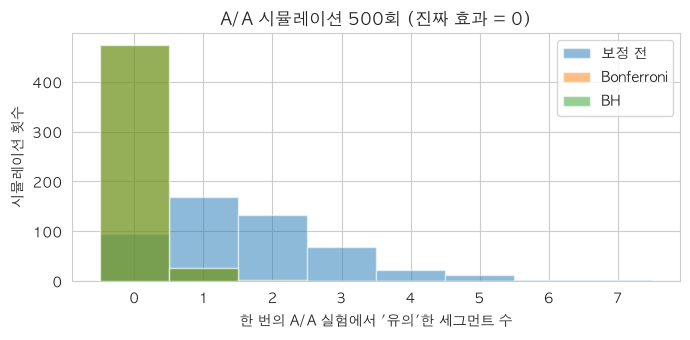

In [42]:
# 시뮬레이션마다 나온 거짓 양성 개수 분포
fig, ax = plt.subplots(figsize=(7, 3.5))
bins = np.arange(0, max(res["보정 전"]) + 2) - 0.5
for k in ["보정 전", "Bonferroni", "BH"]:
    ax.hist(res[k], bins=bins, alpha=0.5, label=k)
ax.set(xlabel="한 번의 A/A 실험에서 '유의'한 세그먼트 수", ylabel="시뮬레이션 횟수",
       title=f"A/A 시뮬레이션 {n_sim}회 (진짜 효과 = 0)")
ax.legend(); plt.tight_layout(); plt.show()

- 보정 전(파랑)은 한 실험에서 0~5개까지 "유의"가 퍼져 나옴.
- 보정 후(주황·초록)는 거의 전부 0개에 몰려 있음 → 가짜 발견이 사라짐.

**결론 (5-C)**
- 효과가 **0인** A/A 실험에서도 31개 세그먼트를 보정 없이 검정하면 평균 약 1.6개가 "유의"하고, 실험의 약 80%에서 **최소 1개 이상**의 가짜 발견이 나옵니다 (이론값 1 − 0.95³¹ ≈ 79.6%와 일치). → "월요일 저녁에 광고 효과가 특히 크다!" 같은 주장은 쉽게 만들어집니다.
- Bonferroni / BH 보정 후에는 "1개 이상 거짓 양성" 비율이 약 5% 수준으로 돌아옵니다 (전부 귀무가설이 참일 때 BH의 FDR = FWER).
- **실제 데이터:** 보정 전 31개 중 13개가 유의했지만, Bonferroni 후 4개, BH 후 5개만 남습니다. 나머지 세그먼트가 유의하지 않은 것은 효과가 없어서라기보다 세그먼트별 PSA 인원이 수백~수천 명뿐이라 **검정력이 부족**하기 때문입니다 (대부분 차이의 방향은 양수).
- 세그먼트 결과는 **탐색적 결과**로만 다룹니다. "화요일에 효과가 가장 크다" 같은 결론은 사전 지정되지 않았으므로 별도 실험으로 확인해야 합니다. (4-4의 Breslow-Day 검정도 요일별 효과 차이를 시사하지만 마찬가지로 탐색적 정보입니다.)

---
## 5-D. 비용까지 따져 보기

> "유의하다" ≠ "도입할 만하다". 전환 1건의 가치와 광고 비용을 **가정**하고, 얼마 이상 올라야 이익인지 계산합니다.
> ⚠️ 아래 금액은 **설명을 위한 가정값**입니다. 실제 의사결정에서는 재무팀 숫자로 바꾸고, 원칙적으로 **실험 전에** 정해야 합니다.

| 가정 | 값 | 설명 |
|---|---|---|
| 전환 1건의 가치 $V$ | 30,000원 | 구매 1건당 공헌이익(매출 − 원가) |
| 광고 1회 노출 비용 $c$ | 5원 | CPM 5,000원 |
| PSA 비용 | 0원 | 공익광고는 무료로 가정 |
| 1인당 평균 노출 수 | 광고 그룹 평균 | 데이터에서 계산 |
| 캠페인 고정비 $F$ | 10,000,000원 | 소재 제작 등 |
| 출시 시 도달 인원 $N$ | 1,000,000명 | |

**손익분기 상승폭:** $\Delta p^* = \dfrac{c \cdot \overline{\text{ads}} + F/N}{V}$ → 전환율이 이 이상 올라야 광고가 이익.

In [43]:
# ── 가정값 (바꿔 가며 민감도를 볼 수 있음) ─────────────────────────
V        = 30_000      # 전환 1건 가치 (원)
c_ad     = 5           # 광고 1회 노출 비용 (원)
F        = 10_000_000  # 고정비 (원)
N_launch = 1_000_000   # 출시 시 도달 인원
avg_ads  = ad_ads.mean()   # 1인당 평균 노출 수 (광고 그룹)

cost_per_user = c_ad * avg_ads + F / N_launch     # 1인당 광고 비용
breakeven_pp  = cost_per_user / V                  # 손익분기 상승폭 (비율 단위)

# 1인당 증분 이익 = V × Δp − 비용, Δp 의 신뢰구간을 그대로 대입
profit_per_user = V * diff - cost_per_user
profit_ci = V * np.array(ci_diff_newc) - cost_per_user

print(f"1인당 평균 노출 {avg_ads:.1f}회 → 1인당 비용 {cost_per_user:,.1f}원")
print(f"손익분기 상승폭 Δp* = {breakeven_pp*100:.3f}%p  (상대 {breakeven_pp/p_psa:.1%} 상승 필요)")
print(f"관측 상승폭        = {diff*100:.3f}%p, 95% CI [{ci_diff_newc[0]*100:.3f}, {ci_diff_newc[1]*100:.3f}]%p")
print(f"1인당 증분 이익    = {profit_per_user:,.1f}원, 95% CI [{profit_ci[0]:,.1f}, {profit_ci[1]:,.1f}]원")
print(f"{N_launch:,}명 도달 시 증분 이익 ≈ {profit_per_user*N_launch/1e6:,.1f}백만원 "
      f"(95% CI {profit_ci[0]*N_launch/1e6:,.1f} ~ {profit_ci[1]*N_launch/1e6:,.1f}백만원)")

if ci_diff_newc[0] > breakeven_pp:   verdict = "CI 하한도 손익분기보다 큼 → 도입 권장"
elif ci_diff_newc[1] < breakeven_pp: verdict = "CI 상한도 손익분기보다 작음 → 도입 비권장"
else:                                verdict = "CI가 손익분기를 포함 → 불확실 (추가 데이터 필요)"
print("판정:", verdict)

1인당 평균 노출 24.8회 → 1인당 비용 134.1원
손익분기 상승폭 Δp* = 0.447%p  (상대 25.0% 상승 필요)
관측 상승폭        = 0.769%p, 95% CI [0.587, 0.936]%p
1인당 증분 이익    = 96.7원, 95% CI [42.1, 146.7]원
1,000,000명 도달 시 증분 이익 ≈ 96.7백만원 (95% CI 42.1 ~ 146.7백만원)
판정: CI 하한도 손익분기보다 큼 → 도입 권장


- ⚠️ 금액은 **설명용 가정값**입니다 (전환 1건 3만 원, 광고 1회 5원, 고정비 1천만 원, 100만 명 도달).
- **1인당 비용 134원** = 24.8회 × 5원 + 고정비 1인당 10원.
- **손익분기 0.447%p**: 전환율이 이만큼 올라야 비용을 회수 (134원 ÷ 3만 원).
- 관측 효과 0.769%p, 신뢰구간 하한 0.587%p > 0.447%p → **불확실성을 감안해도 이익.**
- 1인당 이익 96.7원 → 100만 명이면 **약 9,700만 원** (신뢰구간 약 4,200만 ~ 1억 4,700만 원).

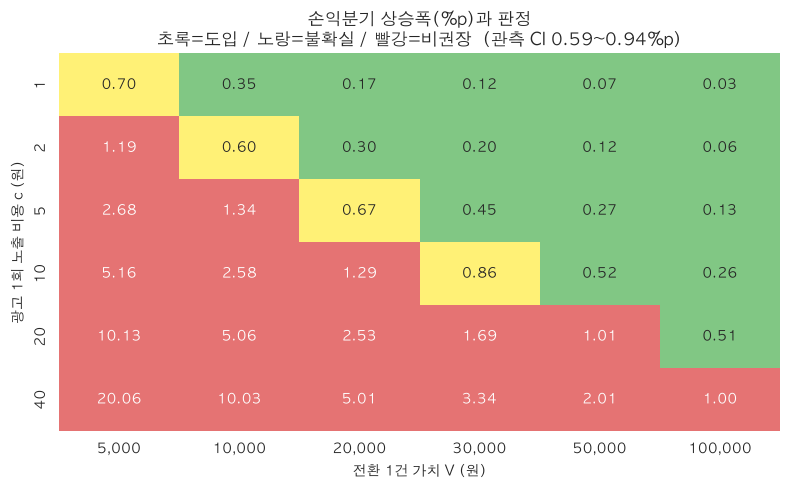

In [44]:
# ── 민감도 분석: 전환 가치 V × 노출 단가 c 조합별 판정 ────────────────
V_grid = np.array([5_000, 10_000, 20_000, 30_000, 50_000, 100_000])
c_grid = np.array([1, 2, 5, 10, 20, 40])
lo, hi = ci_diff_newc

decision = np.zeros((len(c_grid), len(V_grid)))
annot = np.empty_like(decision, dtype=object)
for i, c in enumerate(c_grid):
    for j, v in enumerate(V_grid):
        be = (c * avg_ads + F / N_launch) / v                  # 해당 조합의 손익분기 (비율)
        decision[i, j] = 2 if lo > be else (0 if hi < be else 1)
        annot[i, j] = f"{be*100:.2f}"

fig, ax = plt.subplots(figsize=(8, 5))
cmap = plt.matplotlib.colors.ListedColormap(["#e57373", "#fff176", "#81c784"])
sns.heatmap(decision, annot=annot, fmt="", cmap=cmap, vmin=0, vmax=2, cbar=False, ax=ax,
            xticklabels=[f"{v:,}" for v in V_grid], yticklabels=c_grid)
ax.set(xlabel="전환 1건 가치 V (원)", ylabel="광고 1회 노출 비용 c (원)",
       title=f"손익분기 상승폭(%p)과 판정\n초록=도입 / 노랑=불확실 / 빨강=비권장  (관측 CI {lo*100:.2f}~{hi*100:.2f}%p)")
plt.tight_layout(); plt.show()

- 칸 안 숫자 = 그 조합(전환 가치 × 노출 단가)에서의 **손익분기 상승폭(%p)**.
    - 🟩 초록: 신뢰구간 하한도 손익분기보다 큼 → 도입
    - 🟨 노랑: 신뢰구간이 손익분기를 포함 → 불확실
    - 🟥 빨강: 신뢰구간 상한보다도 큼 → 비권장.
- 예: 전환 가치 3만 원이면 노출 단가 5원은 초록, 10원은 노랑, 20원은 빨강.
- 핵심: **같은 실험 결과도 비용 구조에 따라 결론이 뒤집힐 수 있다.** "유의하다 ≠ 도입할 만하다".

In [45]:
# ── 시나리오: 고노출 사용자(5-B의 IQR 이상치)를 뺀 사용자만 대상으로 하면? ──
# 효과는 작아지지만 노출 수도 적어 비용도 줄어듦 → 둘 다 반영해 다시 계산
xa_t = int(df_trim.loc[df_trim.group == "ad", "converted"].sum());  na_t = int((df_trim.group == "ad").sum())
xp_t = int(df_trim.loc[df_trim.group == "psa", "converted"].sum()); np_t = int((df_trim.group == "psa").sum())
diff_t = xa_t / na_t - xp_t / np_t
ci_t = confint_proportions_2indep(xa_t, na_t, xp_t, np_t, method="newcomb", compare="diff", alpha=ALPHA)
avg_ads_t = df_trim.loc[df_trim.group == "ad", "total_ads"].mean()
be_t = (c_ad * avg_ads_t + F / N_launch) / V

print(f"평균 노출 {avg_ads_t:.1f}회 → 손익분기 {be_t*100:.3f}%p")
print(f"관측 상승폭 {diff_t*100:.3f}%p, 95% CI [{ci_t[0]*100:.3f}, {ci_t[1]*100:.3f}]%p")
print("판정:", "도입 권장" if ci_t[0] > be_t else ("도입 비권장" if ci_t[1] < be_t else "불확실 (CI가 손익분기 포함)"))

평균 노출 15.2회 → 손익분기 0.286%p
관측 상승폭 0.279%p, 95% CI [0.129, 0.411]%p
판정: 불확실 (CI가 손익분기 포함)


- 고노출 사용자를 빼면 평균 노출이 15.2회로 줄어 비용도 줄고, **손익분기는 0.286%p**로 낮아진다.
- 그런데 효과도 0.279%p로 줄어서 **손익분기와 거의 같음**. 신뢰구간 [0.13, 0.41]이 손익분기를 포함 → **불확실**.
- 의미: 이익의 대부분이 **많이 노출된 사용자**에게서 나온다. 출시 후 노출 구간별 성과를 지켜봐야 할 것이다.

**결론 (5-D)**
- 가정(전환 가치 3만 원, 노출당 5원, 고정비 1천만 원)에서는 손익분기 상승폭이 약 **0.45%p**(상대 +25%)이고, 관측 효과의 **95% CI 하한(약 0.59%p)도 이보다 큽니다** → 100만 명 도달 시 증분 이익 약 9,700만 원(95% CI 약 4,200만~1억 4,700만 원), 광고 도입이 이익일 가능성이 높습니다.
- 하지만 민감도 표가 보여주듯 전환 가치가 **2만 원이면 불확실, 1만 원 이하면 손해**가 되고, 노출 단가가 **10원이면 불확실, 20원 이상이면 손해**입니다(V = 3만 원 기준). 같은 통계 결과로도 비용 구조에 따라 결론이 뒤집힙니다.
- **고노출 사용자를 뺀 시나리오**에서는 평균 노출이 약 15회로 줄어 손익분기도 약 0.29%p로 낮아지지만, 관측 효과(약 0.28%p, 95% CI 0.13~0.41%p)가 손익분기와 거의 같아 **"불확실"** 판정입니다. → 이익의 대부분이 고노출 사용자에게서 나온다는 뜻이므로, 출시 후 노출 구간별 성과를 모니터링해야 합니다. 통계적 유의성은 같아도 의사결정은 **비용 구조**에 따라 뒤집힙니다.
- 원칙적으로 이 손익분기값(= 실무적으로 의미 있는 최소 효과)은 실험 **설계 단계**에서 정하고, 5-A의 MDE가 이 값보다 작도록 표본을 잡아야 합니다. 이번 실험은 MDE(≈0.26%p) < 손익분기(≈0.45%p)라 설계상으로도 판단 가능한 실험이었습니다.

---
# 6️⃣ 의사결정으로 마무리

In [46]:
# ── 최종 수치 요약 (아래 텍스트 셀의 숫자가 이 출력과 일치하는지 확인용) ──
final = pd.Series({
    "표본 (ad / psa)": f"{n_ad:,} / {n_psa:,}",
    "전환율 (ad / psa)": f"{p_ad:.2%} / {p_psa:.2%}",
    "절대 차이 [95% CI]": f"{diff*100:+.2f}%p [{ci_diff_newc[0]*100:.2f}, {ci_diff_newc[1]*100:.2f}]",
    "상대 차이 [95% CI]": f"{ratio:.2f}배 ({lift:+.0%}) [{ci_ratio[0]:.2f}, {ci_ratio[1]:.2f}]",
    "검정": f"χ²({dof}) = {chi2:.2f}, p = {p_chi:.1e}",
    "효과 크기": f"Cramér's V = {cramer_v:.3f}, Cohen's h = {cohen_h:.3f}",
    "요일 층화 OR (CMH)": f"{st.oddsratio_pooled:.2f} (crude {crude_or:.2f})",
    "MDE (80% power)": f"{mde_pp*100:.2f}%p",
    "손익분기 상승폭 (가정)": f"{breakeven_pp*100:.2f}%p",
})
final.to_frame("값")

,값
표본 (ad / psa),"564,577 / 23,524"
전환율 (ad / psa),2.55% / 1.79%
절대 차이 [95% CI],"+0.77%p [0.59, 0.94]"
상대 차이 [95% CI],"1.43배 (+43%) [1.30, 1.58]"
검정,"χ²(1) = 54.32, p = 1.7e-13"
효과 크기,"Cramér's V = 0.010, Cohen's h = 0.053"
요일 층화 OR (CMH),1.44 (crude 1.44)
MDE (80% power),0.26%p
손익분기 상승폭 (가정),0.45%p


### 1. 질문과 가설 — 무엇을 알고 싶었나
- **질문:** PSA 대신 광고를 보여주면 구매 전환율이 높아지는가?
- $H_0: p_{ad} = p_{psa}$, $H_1: p_{ad} \neq p_{psa}$, 양측, $\alpha = 0.05$. 1차 지표는 `converted` 하나로 사전 지정했고, 분석 도중 바꾸지 않았다.

### 2. 데이터 위생 점검 — 무엇을 어떻게 정제했나
- 588,101행, 결측 0, `user_id` 중복 0, 다중 그룹 배정 0, 라벨 이상값 0 → **행 제거 없음 (588,101 → 588,101)**. 행 번호 컬럼(`Unnamed: 0`)만 제거.
- **SRM:** 50:50 기준으로는 크게 어긋나지만 이는 의도된 불균형 설계(광고 다수, PSA 소수) 때문. 관측 비율이 96.00:4.00과 사실상 일치해 정상 배정으로 판단.
- 요일·시간대별 PSA 비율이 3~5% 사이에서 통계적으로 다르게 나타났으나(V ≈ 0.02) 요일 층화 CMH 검정에서도 결론이 동일.

### 3. 검정 선택 근거 — 왜 그 검정인가
- 성공 지표가 **비율**(전환 여부)이고 비교 집단이 **2개** → **카이제곱 독립성 검정**(두 비율 z-검정과 동치). 정규성·등분산은 해당 없고, 대신 독립성(중복 없음)과 기대도수 ≥ 5(최소 칸도 수백)를 확인.

### 4. 결과 — 점추정 · 신뢰구간 · 효과 크기
- 전환율 **2.55% (광고) vs 1.79% (PSA)**.
- **절대 차이 +0.77%p [95% CI 0.59–0.94%p]**, **상대 차이 1.43배 (+43%) [95% CI 1.30–1.58배]**.
- χ²(1) = 54.32, **p < .001**. Cramér's V ≈ 0.010, Cohen's h ≈ 0.053 → 관례 기준으로는 "매우 작은" 효과지만, 기저율이 낮아 상대적으로는 큰 상승.
- 강건성: 요일 층화(CMH: 오즈비 1.44 → 1.44)와 부트스트랩 CI는 같은 결론. **고노출 사용자(상위 약 9%)를 빼면 효과가 +0.28%p (1.26배)로 줄지만 여전히 유의** → 방향은 견고하나 크기는 고노출 사용자에 크게 의존.

### 5. 의사결정 — ✅ **출시 (광고 캠페인 집행)**
- **통계적 근거:** 효과가 0일 가능성은 매우 낮고, 신뢰구간 전체가 양수.
- **검정력 근거:** MDE ≈ 0.26%p로 이 실험은 관측 수준의 효과를 잡기에 충분한 힘이 있었음.
- **사업적 근거 (가정 기반):** 손익분기 상승폭 ≈ 0.45%p < 신뢰구간 하한 ≈ 0.59%p → 불확실성을 감안해도 이익 쪽.
- **조건:** 실제 전환 가치·광고 단가로 5-D를 다시 계산해 CI 하한이 여전히 손익분기를 넘을 때. 전환 가치가 2만 원 수준이거나 노출 단가가 10원 수준이면 판단이 불확실해지고, 그보다 나쁘면 **보류**로 바뀜. 출시 후에도 일부 사용자에게 PSA를 유지하는 holdout 그룹으로 효과를 계속 모니터링 권장. 특히 저노출 사용자만 보면 손익이 거의 분기점이라(5-D 시나리오), 노출 구간별 성과를 함께 추적.

### 6. 한계 — 이 결론이 기대는 가정, 이 데이터로 알 수 없는 것
- **무작위 배정 가정:** 캐글 문서에 배정 방식과 정확한 의도 비율이 없다. 96:4를 의도 비율로 본 것은 관측값에 근거한 추정이고, 요일·시간대별 배정 비율의 작은 차이가 있었다. 인과 해석(광고가 전환을 *일으켰다*)은 배정이 무작위였다는 가정에 기대고 있다.
- **비교 대상이 "광고 없음"이 아니라 "PSA"이다.** 결과는 "PSA 대비 광고의 효과"이며, 아무것도 안 보여준 경우와의 차이는 알 수 없다.
- **실험 기간·전환 정의 정보 없음:** 언제, 얼마 동안 진행됐는지, "전환"이 어떤 구매를 뜻하는지 모른다. 신규성 효과(novelty effect)나 장기 효과는 확인할 수 없다.
- **`total_ads`, `most_ads_day/hour`는 배정 이후 관측된 변수**라서, 이를 이용한 분석(5-B, 5-C)은 인과 해석이 아닌 탐색적 결과다. "노출이 많을수록 전환이 높다" 같은 결론은 이 실험으로 말할 수 없다.
- **효과의 이질성:** 효과의 상당 부분이 고노출 사용자에게서 나온다(5-B). 출시 대상의 노출 분포가 실험과 다르면 실제 효과도 달라질 수 있다.
- **불균형 설계:** PSA 그룹이 4%뿐이라 검정력이 작은 쪽에 묶여 있다. 세그먼트 단위의 작은 효과는 이 표본으로 신뢰성 있게 추정하기 어렵다.
- **비용 분석은 가정값**이다. 실제 수치에 따라 결론(출시/보류)이 바뀔 수 있다.
- **일반화:** 이 회사·이 시기·이 사용자 집단의 결과다. 다른 제품·채널·시즌에 그대로 적용된다고 보장할 수 없다.

> 한줄정리: "무작위 배정이 지켜졌다는 가정 아래, 광고는 PSA 대비 전환율을 0.59~0.94%p (약 1.30~1.58배) 높였다고 말할 수 있으며, 가정한 비용 구조에서는 집행할 만하다."